# Effective Point Spread Function (ePSF) Model with `photutils`

This notebook demonstrates how to open a Roman WFI calibrated exposure (L2 `.asdf` file) and its associated source catalog (L4 `.parquet` file), select isolated and unsaturated stars, extract star cutouts, and build an effective PSF (ePSF) model using `photutils.psf.EPSFBuilder`.

In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [3]:
import os
import asdf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

from astropy.table import Table
from astropy.nddata import NDData
from astropy.coordinates import SkyCoord
from astropy import units as u
from astropy.stats import sigma_clipped_stats
from astropy.stats import SigmaClip
from astropy.visualization import simple_norm

from photutils.psf import extract_stars, EPSFBuilder

from astroquery.mast import MastMissions, Observations
from roman_cuts.com import query_mast_files
from roman_cuts.com.io import _open_asdf, open_parquet

from roman_datamodels.dqflags import pixel

## 1. Query or Specify the ASDF Image and Parquet Catalog

You can either query MAST for matching L2 (`_cal.asdf`) and L4 (`_cat.parquet`) products or provide local file paths directly.

In [4]:
# Authenticate with MAST (if streaming from RRN / MAST)
load_dotenv("/teams/romcom/data/jmartinez/my_crds_path.env", override=True)
token = os.environ.get("MAST_API_TOKEN", "")

mission = MastMissions(mission="roman")
if token:
    mission.login(token=token)
Observations.enable_cloud_dataset()

INFO: MAST API token accepted, welcome Jorge Martinez-Palomera [astroquery.mast.auth]
INFO: Using the S3 STScI public dataset [astroquery.mast.cloud]


In [5]:
pid = 1055
detector = 4
filter_name = "F146"
observation = 3
visit = 1

# Query L2 calibrated images (_cal.asdf)
products_l2, _ = query_mast_files(
    program_id=pid,
    detector=detector,
    filter_name=filter_name,
    # observation=observation,
    # visit=visit,
    mission=mission,
    file_type="l2",
)

# Query L4 source catalogs (_cat.parquet)
products_l4, _ = query_mast_files(
    program_id=pid,
    detector=detector,
    filter_name=filter_name,
    # observation=observation,
    # visit=visit,
    mission=mission,
    file_type="l4",
)

print(f"Found {len(products_l2)} L2 images and {len(products_l4)} L4 catalogs.")

Fetching products for 1052 unique datasets in 2 batches ... [Done]
INFO: 19373 of 27014 products were duplicates. Only returning 7641 unique product(s). [astroquery.mast.utils]
INFO: To return all products, use `MastMissions.get_product_list` [astroquery.mast.missions]
Fetching products for 1052 unique datasets in 2 batches ... [Done]
INFO: 19373 of 27014 products were duplicates. Only returning 7641 unique product(s). [astroquery.mast.utils]
INFO: To return all products, use `MastMissions.get_product_list` [astroquery.mast.missions]
Found 1052 L2 images and 1052 L4 catalogs.


In [6]:
# Pick an L2 image and match its corresponding L4 parquet catalog by exposure prefix
asdf_filename = products_l2["filename"][10]
prefix = asdf_filename.replace("_cal.asdf", "")

matching_cats = [f for f in products_l4["filename"] if prefix in str(f)]
parquet_filename = matching_cats[0] if matching_cats else products_l4["filename"][0]

print("ASDF file   :", asdf_filename)
print("Parquet file:", parquet_filename)

ASDF file   : r0105501001001012002_0001_wfi04_f146_cal.asdf
Parquet file: r0105501001001012002_0001_wfi04_f146_cat.parquet


## 2. Load the Image Data and Source Catalog

Open the ASDF file to extract the 2D science image, uncertainty/DQ arrays, and GWCS, and load the Parquet source catalog into a `pandas.DataFrame`.

In [7]:
# Open the L2 ASDF file (works with MAST product names, s3:// URIs, or local paths)
with _open_asdf(asdf_filename, mission=mission) as af:
    data = np.asarray(af["roman"]["data"], dtype=np.float64).copy()
    dq = np.asarray(af["roman"]["dq"]).copy() if "dq" in af["roman"] else None
    gwcs = af["roman"]["meta"]["wcs"]

print(f"Image shape: {data.shape}")

Image shape: (4088, 4088)


In [8]:
# Load the Parquet catalog (local file path or streamed from MAST via open_parquet)
if os.path.exists(str(parquet_filename)):
    cat_df = pd.read_parquet(parquet_filename)
else:
    cat_df = open_parquet(parquet_filename, token=token)

print(f"Total sources in catalog: {len(cat_df)}")
cat_df.head()

Total sources in catalog: 3350


,label,flagged_spatial_id,x_centroid,y_centroid,x_centroid_err,y_centroid_err,x_centroid_win,y_centroid_win,x_centroid_win_err,y_centroid_win_err,...,segment_flux_err,kron_flux,kron_flux_err,kron_abmag,kron_abmag_err,warning_flags,image_flags,psf_flags,psf_gof,dust_ebv
0,1,0,781.591553,2.611302,0.0,0.0,781.614990,2.540103,0.0,0.0,...,64.972778,4.847562e+03,71.971588,22.186192,0.016001,0,0,0,16.280363,0.015840
1,2,0,1351.998047,4.527275,0.0,0.0,1352.079346,4.263459,0.0,0.0,...,331.374481,7.696811e+04,325.450562,19.184223,0.004581,0,0,0,292.045990,0.016650
2,3,0,2080.084473,204.728348,0.0,0.0,2086.709473,244.925278,0.0,0.0,...,31511.875000,2.305833e+08,29862.152344,10.492930,0.000141,0,0,0,3964.037109,0.018032
3,4,0,2605.927002,6.406419,0.0,0.0,2605.843018,6.025903,0.0,0.0,...,126.739769,1.699269e+04,190.259811,20.824345,0.012089,0,0,0,144.287964,0.018981
4,5,0,1183.445068,4.169030,0.0,0.0,1183.413940,4.109094,0.0,0.0,...,52.497448,2.774317e+03,62.700451,22.792110,0.024265,0,0,0,6.363154,0.016385


## 3. Select Suitable Stars for Building the ePSF

To build a clean ePSF, we need stars that are:
1. **Well within the detector boundaries** (excluding a margin of at least half the cutout size).
2. **Bright but unsaturated** (filtering by flux / SNR or peak pixel value).
3. **Point-like and unflagged** (filtering by sharpness, roundness, or quality flags if present).
4. **Isolated** from neighboring sources so cutout stamps do not contain contaminants.

In [9]:
# Resolve detector pixel coordinates (x, y) from the catalog
if {"x_centroid", "y_centroid"}.issubset(cat_df.columns):
    x_all = cat_df["x_centroid"].to_numpy()
    y_all = cat_df["y_centroid"].to_numpy()
elif {"xcentroid", "ycentroid"}.issubset(cat_df.columns):
    x_all = cat_df["xcentroid"].to_numpy()
    y_all = cat_df["ycentroid"].to_numpy()
elif {"x", "y"}.issubset(cat_df.columns):
    x_all = cat_df["x"].to_numpy()
    y_all = cat_df["y"].to_numpy()
elif {"ra", "dec"}.issubset(cat_df.columns):
    coords = SkyCoord(ra=cat_df["ra"].to_numpy() * u.deg, dec=cat_df["dec"].to_numpy() * u.deg)
    x_all, y_all = gwcs.world_to_pixel(coords)
else:
    raise KeyError(f"Could not find coordinate columns in catalog: {list(cat_df.columns)}")

cat_df = cat_df.assign(x_pix=x_all, y_pix=y_all)

In [10]:
cutout_size = 25  # stamp size in pixels (must be odd for EPSFBuilder)
half_size = (cutout_size - 1) // 2
edge_buffer = half_size + 5
ny, nx = data.shape

# 1. Inside detector bounds
mask = (
    np.isfinite(cat_df["x_pix"])
    & np.isfinite(cat_df["y_pix"])
    & (cat_df["x_pix"] > edge_buffer)
    & (cat_df["x_pix"] < (nx - 1 - edge_buffer))
    & (cat_df["y_pix"] > edge_buffer)
    & (cat_df["y_pix"] < (ny - 1 - edge_buffer))
)

# 2. Filter by catalog quality flags / morphology if available
if "flags" in cat_df.columns:
    mask &= cat_df["flags"] == 0
if "is_extended" in cat_df.columns:
    mask &= ~cat_df["is_extended"].astype(bool)
if "sharpness" in cat_df.columns:
    mask &= cat_df["sharpness"].between(0.3, 1.01)
if "roundness1" in cat_df.columns:
    mask &= cat_df["roundness1"].between(-0.5, 0.5)

# 3. Filter by flux / SNR percentile to keep bright, unsaturated stars
flux_col = next(
    (c for c in ["segment_flux", "psf_flux", "aper_flux", "flux", "kron_flux"] if c in cat_df.columns),
    None,
)
if flux_col is not None:
    f_vals = cat_df.loc[mask, flux_col].dropna()
    f_low, f_high = np.nanpercentile(f_vals, [60, 99])
    mask &= cat_df[flux_col].between(f_low, f_high)

candidates = cat_df.loc[mask].copy()

# 4. Isolation criterion: reject sources with any catalog neighbor closer than min_sep pixels
min_sep = cutout_size * 1.2
dx = candidates["x_pix"].to_numpy()[:, None] - cat_df["x_pix"].to_numpy()[None, :]
dy = candidates["y_pix"].to_numpy()[:, None] - cat_df["y_pix"].to_numpy()[None, :]
dist = np.hypot(dx, dy)
# Ignore self-distance (dist == 0)
dist[dist == 0] = np.inf
isolated_mask = np.nanmin(dist, axis=1) > min_sep

selected_stars = candidates.loc[isolated_mask].copy()
print(f"Selected {len(selected_stars)} isolated, high-SNR stars for ePSF construction.")

Selected 314 isolated, high-SNR stars for ePSF construction.


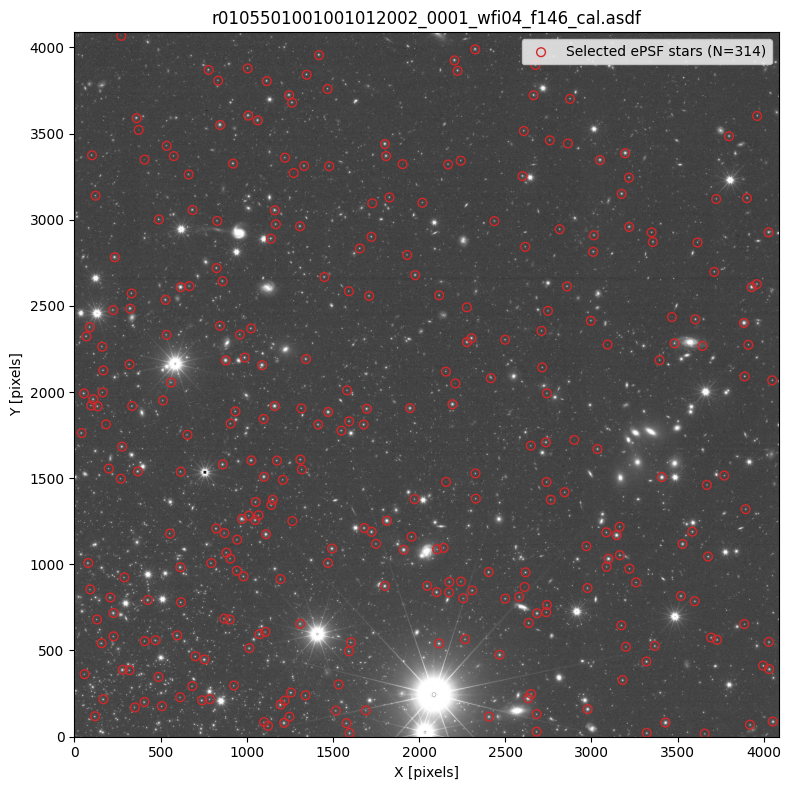

In [11]:
# Visualize the selected stars on the detector image
fig, ax = plt.subplots(figsize=(8, 8))
norm = simple_norm(data, "sqrt", percent=99.0)
ax.imshow(data, origin="lower", cmap="Greys_r", norm=norm)
ax.scatter(
    selected_stars["x_pix"],
    selected_stars["y_pix"],
    s=40,
    facecolors="none",
    edgecolors="tab:red",
    linewidths=1.0,
    label=f"Selected ePSF stars (N={len(selected_stars)})",
)
ax.set_xlabel("X [pixels]")
ax.set_ylabel("Y [pixels]")
ax.set_title(f"{asdf_filename}")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 4. Background Subtraction and Star Cutout Extraction

`photutils.psf.extract_stars` requires background-subtracted image data wrapped in an `astropy.nddata.NDData` object and an `astropy.table.Table` containing columns `'x'` and `'y'`.

To remove empty or bad cutouts (e.g., catalog sources that fall on masked detector regions or have no significant flux in this single L2 exposure), we enforce a **positive net signal above the median background** and require a **minimum number of unmasked pixels with $\mathrm{SNR} > 5$** within each cutout.

In [12]:
# Mask non-finite pixels and bad DQ pixels (bit 0: DO_NOT_USE, bit 1: SATURATED)
bad_mask = ~np.isfinite(data)
if dq is not None:
    bad_mask |= (dq & (pixel.DO_NOT_USE | pixel.SATURATED)) != 0
    # bad_mask = dq > 0

# Estimate and subtract the global background median using unmasked pixels
mean_val, median_val, std_val = sigma_clipped_stats(data, mask=bad_mask, sigma=3.0)
print(f"Background stats — mean: {mean_val:.4f}, median: {median_val:.4f}, std: {std_val:.4f}")

data_bkgsub = data - median_val
data_clean = np.where(bad_mask, 0.0, data_bkgsub)

nddata = NDData(data=data_clean, mask=bad_mask)

# Prepare the star positions table required by extract_stars
stars_tbl = Table()
stars_tbl["x"] = selected_stars["x_pix"].to_numpy()
stars_tbl["y"] = selected_stars["y_pix"].to_numpy()

candidate_stars = extract_stars(nddata, stars_tbl, size=cutout_size)

# Enforce positive signal above median background: require >= min_snr_pixels with SNR > 5
# excluding bad/masked pixels (where star.weights == 0)
snr_threshold = 5.0
min_snr_pixels = 5

valid_cutout_mask = []
for star in candidate_stars:
    valid_pix = (star.weights > 0) & np.isfinite(star.data)
    if not np.any(valid_pix):
        valid_cutout_mask.append(False)
        continue
    snr_cutout = star.data / std_val
    n_snr5 = int(np.sum(valid_pix & (snr_cutout > snr_threshold)))
    positive_signal = np.sum(star.data[valid_pix]) > 0
    valid_cutout_mask.append((n_snr5 >= min_snr_pixels) and positive_signal)

valid_cutout_mask = np.asarray(valid_cutout_mask, dtype=bool)
n_removed = int(np.sum(~valid_cutout_mask))

# Keep only valid non-empty star cutouts and synchronize selected_stars
selected_stars = selected_stars.loc[valid_cutout_mask].copy()
stars_tbl = stars_tbl[valid_cutout_mask]
stars = extract_stars(nddata, stars_tbl, size=cutout_size)

print(
    f"Extracted {len(stars)} valid star cutouts of size {cutout_size}x{cutout_size} "
    f"(removed {n_removed} empty/low-SNR cutouts with < {min_snr_pixels} pixels above SNR > {snr_threshold})."
)

Background stats — mean: 1.0494, median: 1.0435, std: 0.1388
Extracted 311 valid star cutouts of size 25x25 (removed 3 empty/low-SNR cutouts with < 5 pixels above SNR > 5.0).


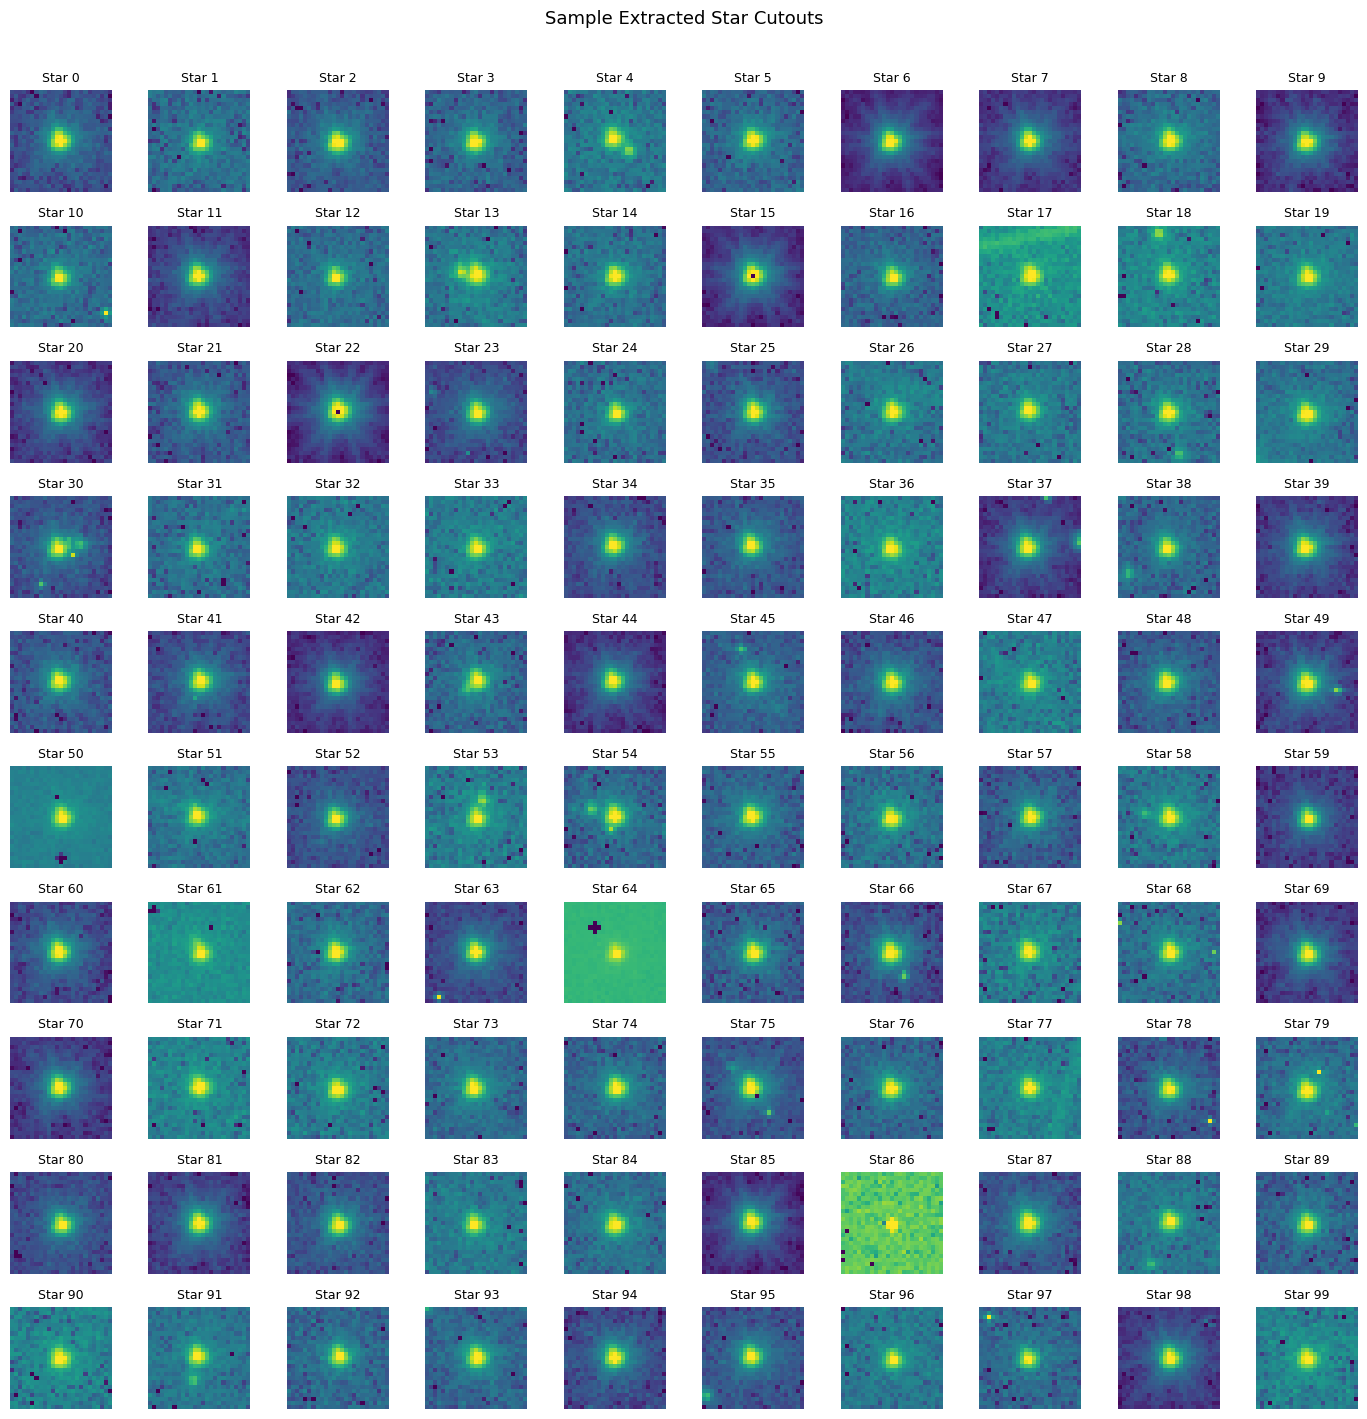

In [13]:
# Inspect a sample of extracted star cutouts
nrows, ncols = 10, 10
n_show = min(nrows * ncols, len(stars))
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 14), squeeze=True)
axes = axes.ravel()

for i in range(nrows * ncols):
    ax = axes[i]
    if i < n_show:
        norm = simple_norm(stars[i], "log", percent=99.0)
        ax.imshow(stars[i], norm=norm, origin="lower", cmap="viridis")
        ax.set_title(f"Star {i}", fontsize=9)
    ax.axis("off")

plt.suptitle("Sample Extracted Star Cutouts", y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

## 5. Build the Effective PSF with `EPSFBuilder`

We now run `EPSFBuilder` with an oversampling factor (commonly `oversampling=2` or `4` for Roman WFI) to iteratively recenter the stars and construct the oversampled ePSF model.

In [14]:
oversampling = 3
maxiters = 5

epsf_builder = EPSFBuilder(
    oversampling=oversampling,
    maxiters=maxiters,
    progress_bar=True,
)

epsf_global, fitted_stars = epsf_builder(stars)
print(f"Built ePSF model with shape: {epsf_global.data.shape} (oversampling={oversampling})")

EPSFBuilder (5 maxiters):   0%|          | 0/5 [00:00<?, ?it/s]

Built ePSF model with shape: (75, 75) (oversampling=3)


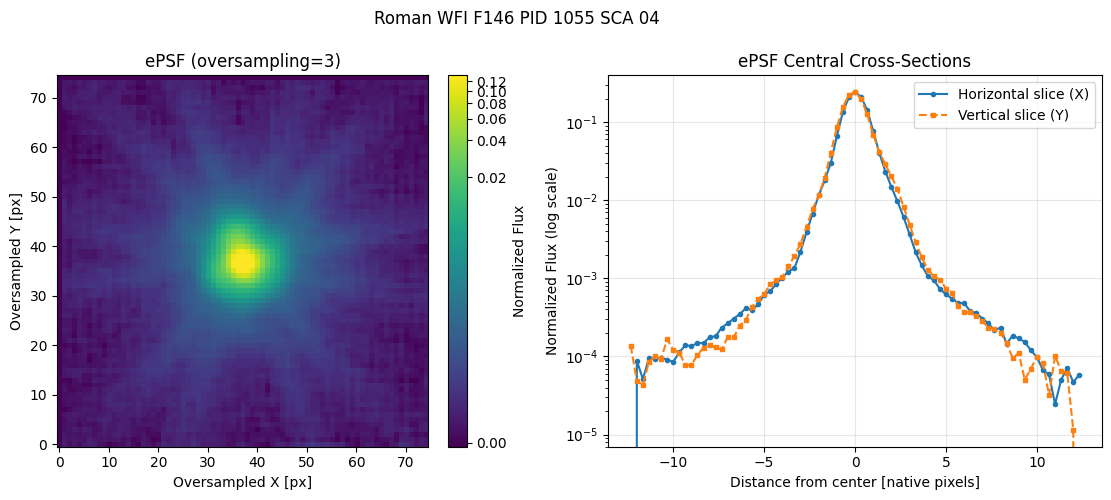

In [15]:
# Visualize the resulting 2D ePSF model and radial / cross-section profiles
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

fig.suptitle(f"Roman WFI {filter_name} PID {pid} SCA {detector:02}", y=0.99)

# Left panel: 2D ePSF image
norm_global = simple_norm(epsf_global.data, "log", percent=99.5)
im = axes[0].imshow(epsf_global.data, norm=norm_global, origin="lower", cmap="viridis")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04, label="Normalized Flux")

axes[0].set_title(f"ePSF (oversampling={oversampling})")
axes[0].set_xlabel("Oversampled X [px]")
axes[0].set_ylabel("Oversampled Y [px]")

# Right panel: 1D slices through the ePSF peak
cy, cx = np.unravel_index(np.nanargmax(epsf_global.data), epsf_global.data.shape)
pix_x = (np.arange(epsf_global.data.shape[1]) - cx) / oversampling
pix_y = (np.arange(epsf_global.data.shape[0]) - cy) / oversampling

axes[1].plot(pix_x, epsf_global.data[cy, :], "o-", ms=3, label="Horizontal slice (X)")
axes[1].plot(pix_y, epsf_global.data[:, cx], "s--", ms=3, label="Vertical slice (Y)")
axes[1].set_yscale("log")
axes[1].set_xlabel("Distance from center [native pixels]")
axes[1].set_ylabel("Normalized Flux (log scale)")
axes[1].set_title("ePSF Central Cross-Sections")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

In [1]:
epsf_global.data.sum()

NameError: name 'epsf_global' is not defined

### Evaluating the Global ePSF at Any Detector Position

The helper function `evaluate_global_epsf()` evaluates the global `epsf` model centered at any sub-pixel coordinate `(x_0, y_0)` on the detector, with the option to sample the model on:
- **`grid="oversampled"`**: The model's high-resolution oversampled grid (spacing `1 / oversampling` native pixels) anchored around `(x_0, y_0)`.
- **`grid="native"`**: The integer detector pixel grid of size `(stamp_size, stamp_size)` surrounding `(x_0, y_0)`.

In [191]:
def evaluate_global_epsf(
    x_0: float,
    y_0: float,
    epsf_model=epsf_global,
    grid: str = "native",
    stamp_size: int = cutout_size,
    flux: float = 1.0,
) -> dict:
    """Evaluate the global ePSF model at any detector coordinate (x_0, y_0).

    Parameters
    ----------
    x_0, y_0 : float
        Target (x, y) pixel position on the detector (0-indexed).
    epsf_model : photutils.psf.EPSFModel
        Global ePSF model returned by EPSFBuilder.
    grid : {'native', 'oversampled'}
        Grid type on which to evaluate the ePSF:
        - 'native': evaluates on the integer detector pixel grid around (x_0, y_0).
        - 'oversampled': evaluates on the model's oversampled grid (step = 1/oversampling)
          anchored at the nearest detector pixel around (x_0, y_0).
    stamp_size : int, optional
        Cutout stamp size in native detector pixels when grid='native' (default: cutout_size).
    flux : float, optional
        Flux scaling factor passed to epsf_model.evaluate (default: 1.0).

    Returns
    -------
    dict
        Dictionary containing:
        - 'psf': 2D array of the evaluated ePSF.
        - 'x_grid', 'y_grid': 2D detector coordinate arrays used for evaluation.
        - 'extent': [xmin, xmax, ymin, ymax] in detector pixel coordinates for plotting.
        - 'grid': Selected grid mode ('native' or 'oversampled').
    """
    xc, yc = int(np.round(x_0)), int(np.round(y_0))
    grid_mode = grid.lower()

    if grid_mode == "native":
        half = stamp_size // 2
        x_1d = np.arange(xc - half, xc + half + 1, dtype=np.float64)
        y_1d = np.arange(yc - half, yc + half + 1, dtype=np.float64)
        step_x = step_y = 1.0
    elif grid_mode == "oversampled":
        ov = np.atleast_1d(epsf_model.oversampling)
        ox, oy = (float(ov[0]), float(ov[0])) if len(ov) == 1 else (float(ov[0]), float(ov[1]))
        ny_psf, nx_psf = epsf_model.data.shape
        half_x = (nx_psf - 1) / (2.0 * ox)
        half_y = (ny_psf - 1) / (2.0 * oy)
        x_1d = np.linspace(xc - half_x, xc + half_x, nx_psf)
        y_1d = np.linspace(yc - half_y, yc + half_y, ny_psf)
        step_x, step_y = 1.0 / ox, 1.0 / oy
    else:
        raise ValueError(f"Unsupported grid='{grid}'. Choose 'native' or 'oversampled'.")

    xx, yy = np.meshgrid(x_1d, y_1d)
    psf_eval = epsf_model.evaluate(x=xx, y=yy, flux=flux, x_0=x_0, y_0=y_0)

    extent = [
        x_1d[0] - 0.5 * step_x,
        x_1d[-1] + 0.5 * step_x,
        y_1d[0] - 0.5 * step_y,
        y_1d[-1] + 0.5 * step_y,
    ]

    return {
        "psf": psf_eval,
        "x_grid": xx,
        "y_grid": yy,
        "extent": extent,
        "grid": grid_mode,
    }

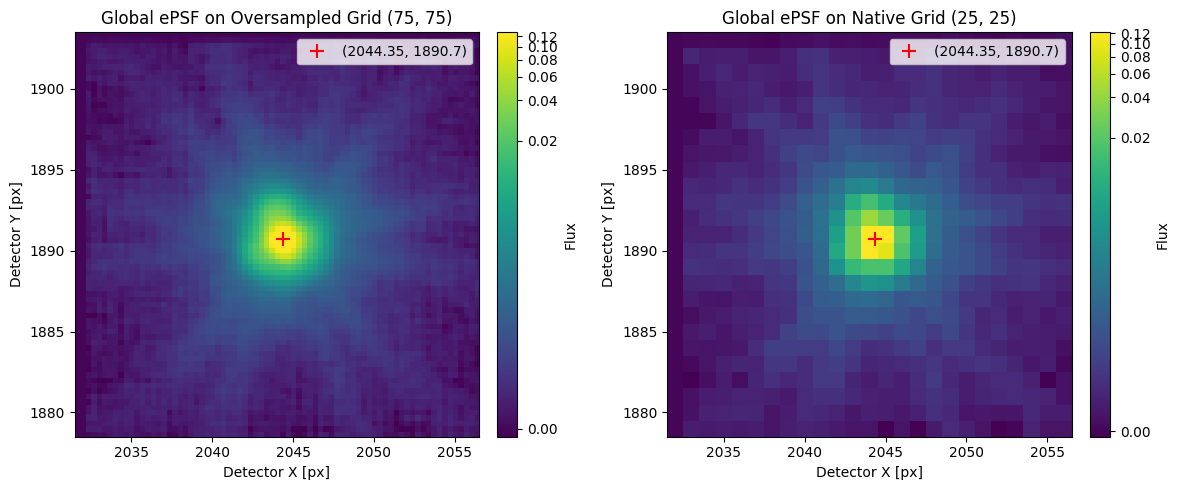

In [192]:
# Example: Evaluate the global ePSF at a sub-pixel detector coordinate (x_0, y_0)
x0_demo, y0_demo = 2044.35, 1890.70

eval_over = evaluate_global_epsf(x0_demo, y0_demo, epsf_global, grid="oversampled")
eval_native = evaluate_global_epsf(x0_demo, y0_demo, epsf_global, grid="native", stamp_size=cutout_size)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: Oversampled grid evaluation
norm_over = simple_norm(eval_over["psf"], "log", percent=99.5)
im0 = axes[0].imshow(
    eval_over["psf"],
    norm=norm_over,
    origin="lower",
    cmap="viridis",
    extent=eval_over["extent"],
)
axes[0].plot(x0_demo, y0_demo, "r+", ms=10, mew=1.5, label=f"({x0_demo}, {y0_demo})")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label="Flux")
axes[0].set_title(f"Global ePSF on Oversampled Grid {eval_over['psf'].shape}")
axes[0].set_xlabel("Detector X [px]")
axes[0].set_ylabel("Detector Y [px]")
axes[0].legend(loc="upper right")

# Right: Native detector grid evaluation
norm_nat = simple_norm(eval_native["psf"], "log", percent=99.5)
im1 = axes[1].imshow(
    eval_native["psf"],
    norm=norm_nat,
    origin="lower",
    cmap="viridis",
    extent=eval_native["extent"],
)
axes[1].plot(x0_demo, y0_demo, "r+", ms=10, mew=1.5, label=f"({x0_demo}, {y0_demo})")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04, label="Flux")
axes[1].set_title(f"Global ePSF on Native Grid {eval_native['psf'].shape}")
axes[1].set_xlabel("Detector X [px]")
axes[1].set_ylabel("Detector Y [px]")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

## 6. Spatially Varying 4x4 Grid ePSF & Spatial Interpolation - [WARNING] WIP

Because the optical PSF varies across the Roman WFI detector field of view, we split the image into a $4 \times 4$ spatial grid and build an independent ePSF model in each grid cell.

We then implement `evaluate_spatial_epsf()`, which selects the closest grid cells around any target pixel coordinate $(x, y)$ and interpolates the ePSF across space using either **polynomial interpolation** (of arbitrary degree) or **B-spline interpolation**.

In [208]:
n_grid_y, n_grid_x = 4, 4
min_stars_per_cell = 5
sigma_clip = SigmaClip()

x_edges = np.linspace(0, nx, n_grid_x + 1)
y_edges = np.linspace(0, ny, n_grid_y + 1)

x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])
y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])

psf_h, psf_w = epsf_global.data.shape
epsf_grid = np.zeros((n_grid_y, n_grid_x, psf_h, psf_w), dtype=np.float64)
epsf_models = np.empty((n_grid_y, n_grid_x), dtype=object)
cell_star_counts = np.zeros((n_grid_y, n_grid_x), dtype=int)

grid_builder = EPSFBuilder(
    oversampling=oversampling,
    maxiters=maxiters,
    progress_bar=False,
    sigma_clip=sigma_clip,
    fit_shape=5,
)

for iy in range(n_grid_y):
    for ix in range(n_grid_x):
        in_cell = (
            (selected_stars["x_pix"] >= x_edges[ix])
            & (selected_stars["x_pix"] < x_edges[ix + 1])
            & (selected_stars["y_pix"] >= y_edges[iy])
            & (selected_stars["y_pix"] < y_edges[iy + 1])
        )
        cell_df = selected_stars[in_cell]

        cell_tbl = Table()
        cell_tbl["x"] = cell_df["x_pix"].to_numpy()
        cell_tbl["y"] = cell_df["y_pix"].to_numpy()

        cell_stars = extract_stars(nddata, cell_tbl, size=cutout_size)
        cell_star_counts[iy, ix] = len(cell_stars)

        if len(cell_stars) >= min_stars_per_cell:
            # use the global ePSF as a start
            cell_epsf, _ = grid_builder.build_epsf(cell_stars, epsf=epsf_global)
            # Match output shape in case of minor border trimming differences
            ch, cw = cell_epsf.data.shape
            if (ch, cw) == (psf_h, psf_w):
                epsf_grid[iy, ix] = cell_epsf.data
            else:
                mh, mw = min(ch, psf_h), min(cw, psf_w)
                epsf_grid[iy, ix, :mh, :mw] = cell_epsf.data[:mh, :mw]
            epsf_models[iy, ix] = cell_epsf
        else:
            # Fallback to global ePSF if cell has insufficient stars
            epsf_grid[iy, ix] = epsf.data.copy()
            epsf_models[iy, ix] = epsf

        print(
            f"Cell (iy={iy}, ix={ix}) center=({x_centers[ix]:.0f}, {y_centers[iy]:.0f}): "
            f"{len(cell_stars)} stars"
        )

Cell (iy=0, ix=0) center=(511, 511): 33 stars
Cell (iy=0, ix=1) center=(1533, 511): 21 stars
Cell (iy=0, ix=2) center=(2555, 511): 23 stars
Cell (iy=0, ix=3) center=(3577, 511): 23 stars
Cell (iy=1, ix=0) center=(511, 1533): 28 stars
Cell (iy=1, ix=1) center=(1533, 1533): 32 stars
Cell (iy=1, ix=2) center=(2555, 1533): 12 stars
Cell (iy=1, ix=3) center=(3577, 1533): 14 stars
Cell (iy=2, ix=0) center=(511, 2555): 21 stars
Cell (iy=2, ix=1) center=(1533, 2555): 14 stars
Cell (iy=2, ix=2) center=(2555, 2555): 16 stars
Cell (iy=2, ix=3) center=(3577, 2555): 16 stars
Cell (iy=3, ix=0) center=(511, 3577): 15 stars
Cell (iy=3, ix=1) center=(1533, 3577): 14 stars
Cell (iy=3, ix=2) center=(2555, 3577): 13 stars
Cell (iy=3, ix=3) center=(3577, 3577): 8 stars


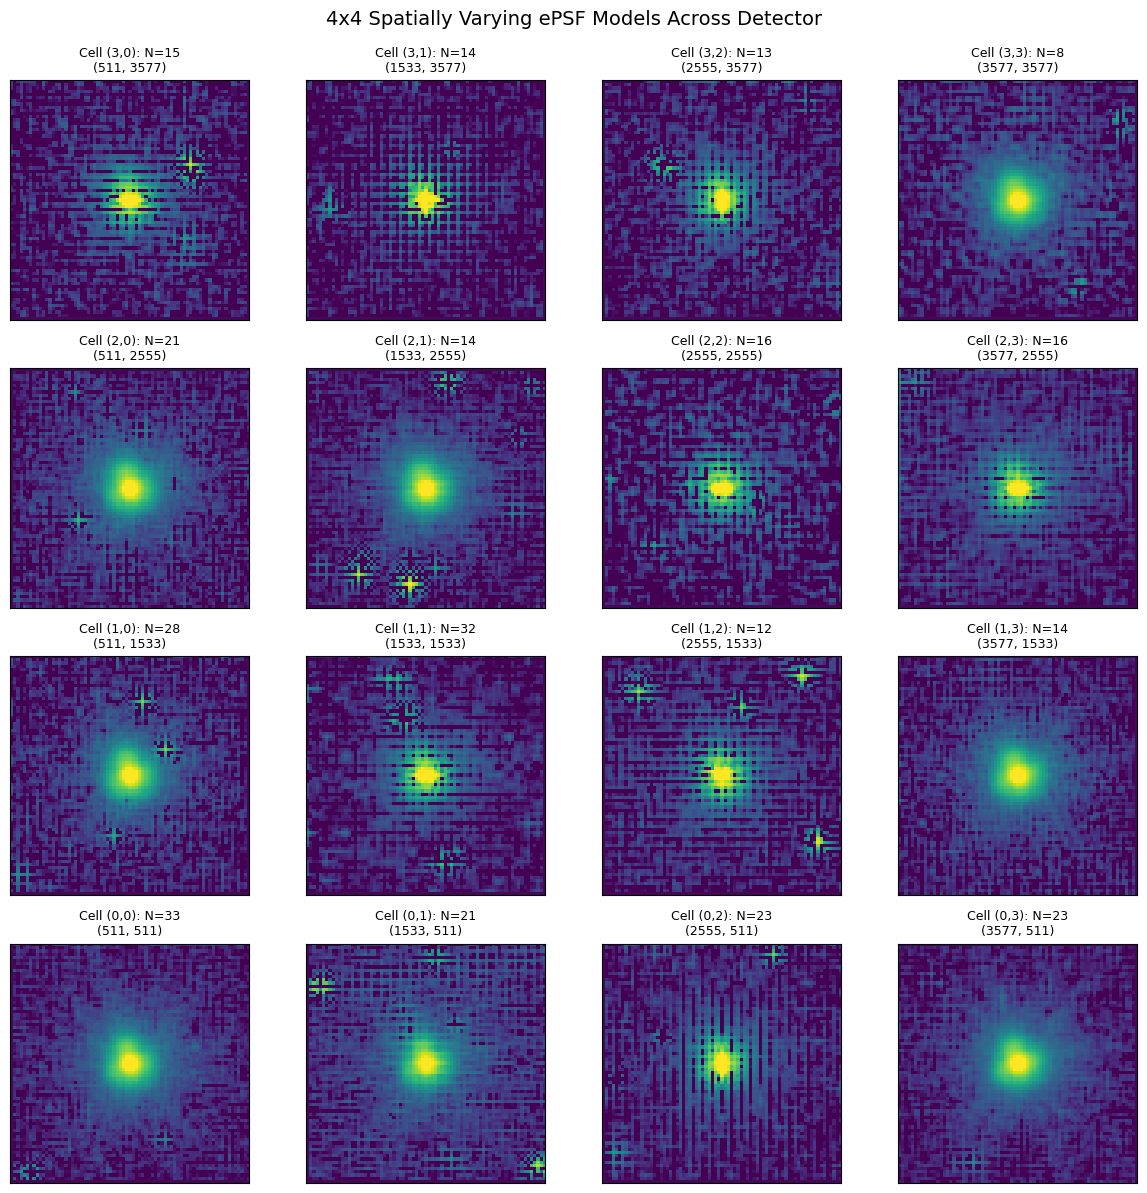

In [209]:
fig, axes = plt.subplots(n_grid_y, n_grid_x, figsize=(12, 12))
norm = simple_norm(epsf_grid.ravel(), "log", percent=99.5)

for iy in range(n_grid_y):
    for ix in range(n_grid_x):
        # Display with iy=0 at the bottom row to match detector (origin='lower') layout
        ax = axes[n_grid_y - 1 - iy, ix]
        cell_data = epsf_grid[iy, ix]
        ax.imshow(cell_data, norm=norm_global, origin="lower", cmap="viridis")
        ax.set_title(
            f"Cell ({iy},{ix}): N={cell_star_counts[iy, ix]}\n"
            f"({x_centers[ix]:.0f}, {y_centers[iy]:.0f})",
            fontsize=9,
        )
        ax.set_xticks([])
        ax.set_yticks([])

fig.suptitle("4x4 Spatially Varying ePSF Models Across Detector", fontsize=14, y=0.99)
plt.tight_layout()
plt.show()

### Spatial Interpolation & Evaluation Function

The function `evaluate_spatial_epsf` below takes any detector pixel location `(x, y)` and:
1. Selects the `n_closest` nearest grid cell centers along $X$ and $Y$ (defaulting to `degree + 1` cells per axis so a local polynomial or B-spline of the requested `degree` can be constructed from the closest grid models).
2. Interpolates the ePSF across the spatial grid using either:
   - **`method="bspline"`**: Tensor-product 1D B-splines (`scipy.interpolate.make_interp_spline`) of order `k = degree` along $Y$ and $X$.
   - **`method="polynomial"`**: Tensor-product Lagrange polynomial interpolation of arbitrary `degree` (`0` = nearest, `1` = bilinear, `2` = biquadratic, `3` = bicubic, etc.).
3. Optionally evaluates the spatially interpolated `EPSFModel` directly on a native detector pixel cutout stamp centered at `(x, y)` (accounting for sub-pixel positioning).

In [210]:
from photutils.psf import ImagePSF
from scipy.interpolate import make_interp_spline


def _lagrange_weights(x_val: float, nodes: np.ndarray) -> np.ndarray:
    """Compute 1D Lagrange basis polynomial weights at x_val for given 1D nodes."""
    k = len(nodes)
    weights = np.ones(k, dtype=np.float64)
    for j in range(k):
        for m in range(k):
            if m != j:
                weights[j] *= (x_val - nodes[m]) / (nodes[j] - nodes[m])
    return weights


def evaluate_spatial_epsf(
    x: float,
    y: float,
    epsf_grid: np.ndarray,
    x_centers: np.ndarray,
    y_centers: np.ndarray,
    method: str = "bspline",
    degree: int = 3,
    n_closest: int | None = None,
    oversampling: int = 4,
    eval_stamp_size: int | None = None,
) -> dict:
    """Evaluate the spatially interpolated ePSF at any detector pixel coordinate (x, y).

    Parameters
    ----------
    x, y : float
        Target pixel coordinates (0-indexed) on the detector image.
    epsf_grid : np.ndarray
        4D array of shape (n_grid_y, n_grid_x, psf_h, psf_w) containing grid ePSF arrays.
    x_centers, y_centers : np.ndarray
        1D arrays of grid cell center coordinates in X and Y.
    method : {'bspline', 'polynomial'}
        Spatial interpolation method ('bspline' or 'polynomial').
    degree : int
        Polynomial or B-spline degree (e.g., 1=linear, 2=quadratic, 3=cubic).
    n_closest : int or None, optional
        Number of closest grid cells per axis to use. If None, uses
        min(len(centers), degree + 1) for local polynomial/B-spline interpolation.
    oversampling : int
        Oversampling factor of the ePSF grid.
    eval_stamp_size : int or None, optional
        If provided, also evaluates the interpolated ImagePSF on an
        (eval_stamp_size x eval_stamp_size) native detector pixel grid around (x, y).

    Returns
    -------
    dict
        Dictionary containing:
        - 'epsf_data': 2D oversampled interpolated ePSF array.
        - 'epsf_model': photutils ImagePSF wrapping the interpolated ePSF.
        - 'ix_closest', 'iy_closest': Grid indices of the closest cells used.
        - 'detector_stamp': 2D native-pixel evaluation around (x, y) if eval_stamp_size is set.
    """
    if degree < 0:
        raise ValueError("degree must be >= 0")

    ny_grid, nx_grid = len(y_centers), len(x_centers)
    k_x = min(degree, nx_grid - 1)
    k_y = min(degree, ny_grid - 1)

    m_x = min(nx_grid, max(k_x + 1, n_closest if n_closest is not None else k_x + 1))
    m_y = min(ny_grid, max(k_y + 1, n_closest if n_closest is not None else k_y + 1))

    # Find the m_x and m_y closest grid centers in X and Y, sorted in ascending coordinate order
    ix_closest = np.sort(np.argsort(np.abs(x_centers - x))[:m_x])
    iy_closest = np.sort(np.argsort(np.abs(y_centers - y))[:m_y])

    sub_x = x_centers[ix_closest]
    sub_y = y_centers[iy_closest]
    sub_grid = epsf_grid[np.ix_(iy_closest, ix_closest)]  # (m_y, m_x, psf_h, psf_w)

    method_lower = method.lower()
    if method_lower == "polynomial":
        # Use the (k + 1) closest nodes for exact degree-k Lagrange polynomial interpolation
        ix_poly = np.sort(np.argsort(np.abs(x_centers - x))[: k_x + 1])
        iy_poly = np.sort(np.argsort(np.abs(y_centers - y))[: k_y + 1])
        wx = _lagrange_weights(x, x_centers[ix_poly])
        wy = _lagrange_weights(y, y_centers[iy_poly])
        sub_poly = epsf_grid[np.ix_(iy_poly, ix_poly)]
        interp_data = np.tensordot(wy, np.tensordot(wx, sub_poly, axes=(0, 1)), axes=(0, 0))
        ix_closest, iy_closest = ix_poly, iy_poly
    elif method_lower in ("bspline", "b-spline", "spline"):
        # Tensor-product B-spline of degree (k_y, k_x) along Y then X
        spline_y = make_interp_spline(sub_y, sub_grid, k=k_y, axis=0)
        temp_y = spline_y(y)  # shape: (m_x, psf_h, psf_w)
        spline_x = make_interp_spline(sub_x, temp_y, k=k_x, axis=0)
        interp_data = spline_x(x)  # shape: (psf_h, psf_w)
    else:
        raise ValueError(f"Unsupported interpolation method '{method}'. Choose 'bspline' or 'polynomial'.")

    epsf_model = ImagePSF(interp_data, oversampling=oversampling)

    result = {
        "epsf_data": interp_data,
        "epsf_model": epsf_model,
        "ix_closest": ix_closest,
        "iy_closest": iy_closest,
        "detector_stamp": None,
        "stamp_extent": None,
    }

    if eval_stamp_size is not None:
        half = eval_stamp_size // 2
        xc, yc = int(np.round(x)), int(np.round(y))
        yy, xx = np.mgrid[yc - half : yc + half + 1, xc - half : xc + half + 1]
        result["detector_stamp"] = epsf_model.evaluate(xx, yy, flux=1.0, x_0=x, y_0=y)
        result["stamp_extent"] = [xc - half - 0.5, xc + half + 0.5, yc - half - 0.5, yc + half + 0.5]

    return result

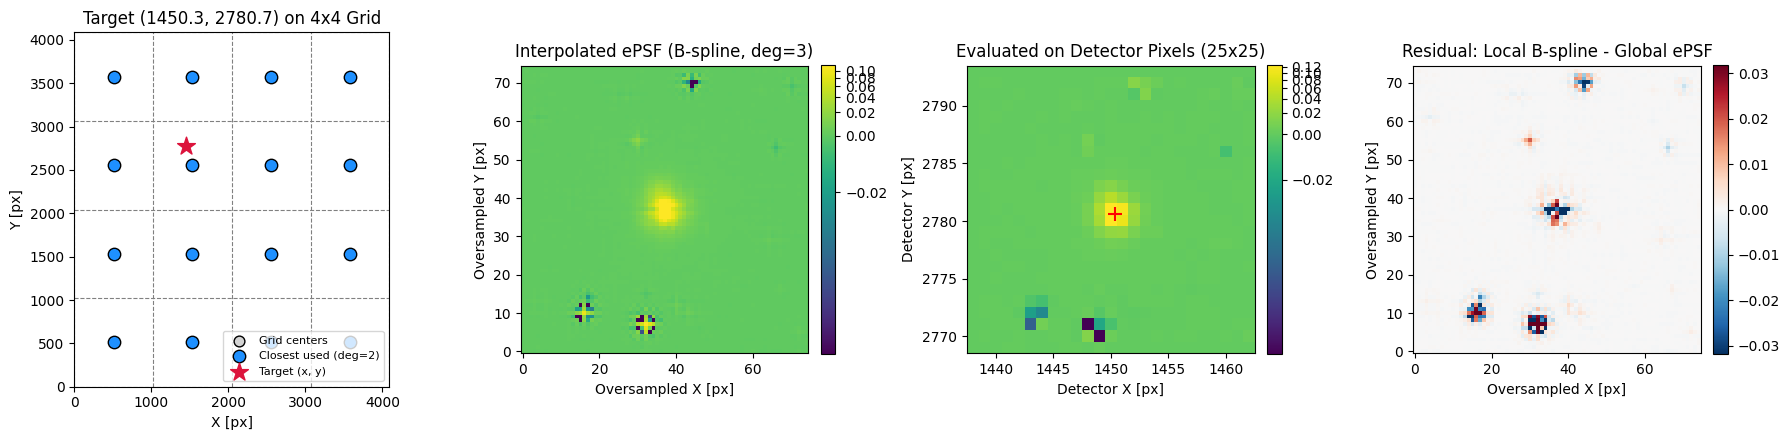

In [213]:
# Evaluate the spatially varying ePSF at an arbitrary detector pixel position
x_target, y_target = 1450.35, 2780.65

res_bspline = evaluate_spatial_epsf(
    x_target,
    y_target,
    epsf_grid,
    x_centers,
    y_centers,
    n_closest=4,
    method="bspline",
    degree=3,
    oversampling=oversampling,
    eval_stamp_size=cutout_size,
)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

# 1. Spatial grid showing target point and closest grid centers used (for degree=2)
ax0 = axes[0]
for xe in x_edges:
    ax0.axvline(xe, color="gray", lw=0.8, ls="--")
for ye in y_edges:
    ax0.axhline(ye, color="gray", lw=0.8, ls="--")
gx, gy = np.meshgrid(x_centers, y_centers)
ax0.scatter(gx, gy, c="lightgray", s=60, edgecolors="k", label="Grid centers")
cx_used, cy_used = np.meshgrid(
    x_centers[res_bspline["ix_closest"]], y_centers[res_bspline["iy_closest"]]
)
ax0.scatter(cx_used, cy_used, c="dodgerblue", s=80, edgecolors="k", label="Closest used (deg=2)")
ax0.scatter([x_target], [y_target], c="crimson", marker="*", s=180, zorder=5, label="Target (x, y)")
ax0.set_xlim(0, nx)
ax0.set_ylim(0, ny)
ax0.set_xlabel("X [px]")
ax0.set_ylabel("Y [px]")
ax0.set_title(f"Target ({x_target:.1f}, {y_target:.1f}) on 4x4 Grid")
ax0.legend(loc="lower right", fontsize=8)

# 2. Interpolated oversampled ePSF (Cubic B-spline)
norm_bs = simple_norm(res_bspline["epsf_data"], "log", percent=99.5)
im1 = axes[1].imshow(res_bspline["epsf_data"], norm=norm_bs, origin="lower", cmap="viridis")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
axes[1].set_title("Interpolated ePSF (B-spline, deg=3)")
axes[1].set_xlabel("Oversampled X [px]")
axes[1].set_ylabel("Oversampled Y [px]")

# 3. Native-pixel detector stamp evaluated at subpixel (x_target, y_target)
stamp = res_bspline["detector_stamp"]
norm_st = simple_norm(stamp, "log", percent=99.5)
im2 = axes[2].imshow(
    stamp,
    norm=norm_st,
    origin="lower",
    cmap="viridis",
    extent=res_bspline["stamp_extent"],
)
axes[2].plot(x_target, y_target, "r+", ms=10, mew=1.5)
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)
axes[2].set_title(f"Evaluated on Detector Pixels ({cutout_size}x{cutout_size})")
axes[2].set_xlabel("Detector X [px]")
axes[2].set_ylabel("Detector Y [px]")

# 4. Difference between Cubic B-spline and Global ePSF
diff = res_bspline["epsf_data"] - epsf_global.data
vmax = np.nanpercentile(np.abs(diff), 99.5)
im3 = axes[3].imshow(diff, origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
plt.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)
axes[3].set_title("Residual: Local B-spline - Global ePSF")
axes[3].set_xlabel("Oversampled X [px]")
axes[3].set_ylabel("Oversampled Y [px]")

plt.tight_layout()
plt.show()

## 7. Building an ePSF Model from Multi-Epoch Cutouts of a Single Star  - [WARNING] WIP

When multiple exposures of the same field are available (e.g., dithered visits or time-domain monitoring), a single star is sampled at slightly different pixel and sub-pixel positions over time.

In this section we:
1. Select a bright, isolated star near the detector center and obtain its sky coordinates $(\alpha, \delta)$.
2. Use `make_cutout()` from `roman_cuts.com.cutout` to extract its cutout across all available L2 observations.
3. Wrap each valid epoch cutout into a `photutils.psf.EPSFStar` using the cutout metadata (`input_position_cutout` and `origin_original`) and build a multi-epoch ePSF model with `EPSFBuilder`.

In [224]:
selected_stars.query("kron_abmag < 19")


,label,flagged_spatial_id,x_centroid,y_centroid,x_centroid_err,y_centroid_err,x_centroid_win,y_centroid_win,x_centroid_win_err,y_centroid_win_err,...,kron_flux_err,kron_abmag,kron_abmag_err,warning_flags,image_flags,psf_flags,psf_gof,dust_ebv,x_pix,y_pix
104,105,0,3429.364990,83.954521,0.0,0.0,3429.219238,83.892250,0.0,0.0,...,638.365845,17.649267,0.002188,0,0,0,906.729736,0.019829,3429.364990,83.954521
107,108,0,1216.415405,82.227791,0.0,0.0,1216.386353,82.102898,0.0,0.0,...,358.417267,18.609119,0.002973,0,0,0,534.793945,0.016431,1216.415405,82.227791
115,116,0,4052.500244,89.867882,0.0,0.0,4052.443359,89.812584,0.0,0.0,...,361.939880,18.655251,0.003132,0,0,0,428.534546,0.020086,4052.500244,89.867882
139,140,0,2405.313965,118.100899,0.0,0.0,2405.344238,118.091370,0.0,0.0,...,365.571472,18.728287,0.003383,0,0,0,387.649048,0.018659,2405.313965,118.100899
217,218,0,1195.602905,188.014496,0.0,0.0,1195.606934,187.915024,0.0,0.0,...,298.901886,18.697180,0.002689,0,0,0,603.274963,0.016394,1195.602905,188.014496
243,244,0,2632.733154,224.350327,0.0,0.0,2632.758301,224.325150,0.0,0.0,...,705.613953,17.383020,0.001893,0,0,0,1075.118774,0.019073,2632.733154,224.350327
443,444,0,4031.203369,394.024384,0.0,0.0,4031.145264,393.961212,0.0,0.0,...,260.008118,18.779257,0.002523,0,0,0,566.067871,0.020255,4031.203369,394.024384
609,610,0,2115.767822,542.718750,0.0,0.0,2115.586914,542.780273,0.0,0.0,...,491.394196,18.492983,0.003661,0,0,0,490.404175,0.018128,2115.767822,542.718750
647,648,0,1041.099365,567.478699,0.0,0.0,1041.004761,567.546692,0.0,0.0,...,385.281708,18.602732,0.003177,0,0,0,454.956207,0.016150,1041.099365,567.478699
797,798,0,226.784714,719.568604,0.0,0.0,226.826584,719.504333,0.0,0.0,...,334.967957,18.636061,0.002848,0,0,0,613.259155,0.015181,226.784714,719.568604


104 0


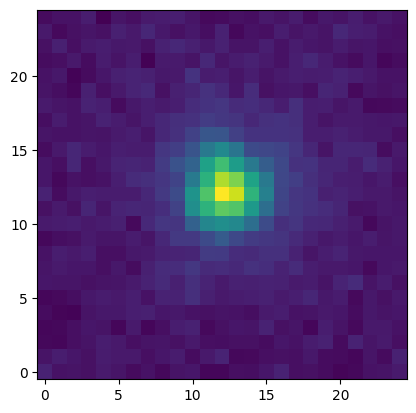

107 1


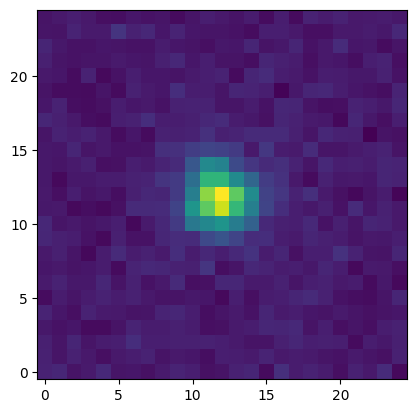

115 2


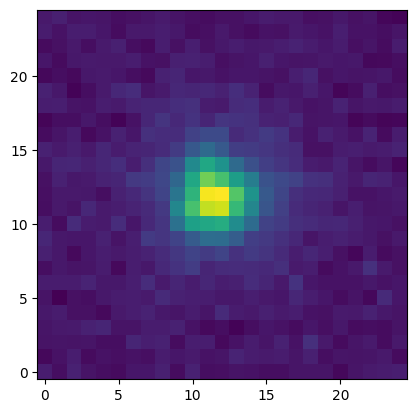

139 3


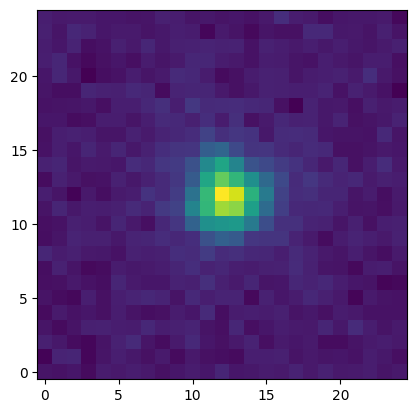

217 4


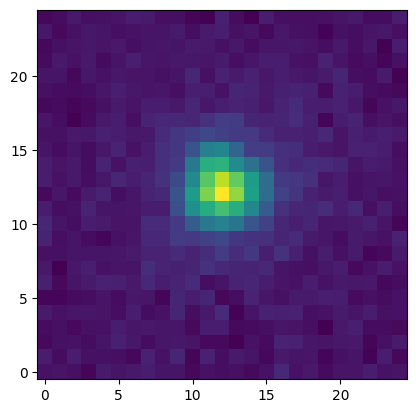

243 5


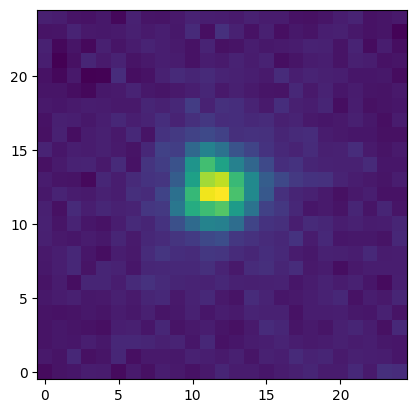

443 6


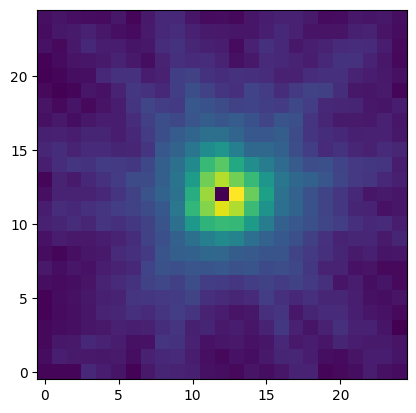

609 7


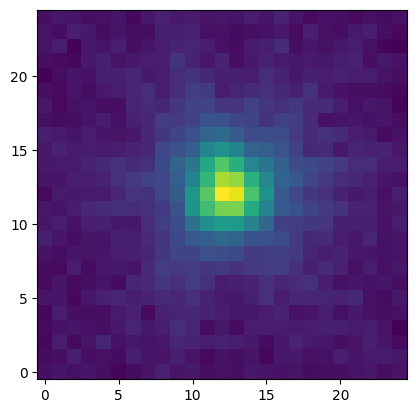

647 8


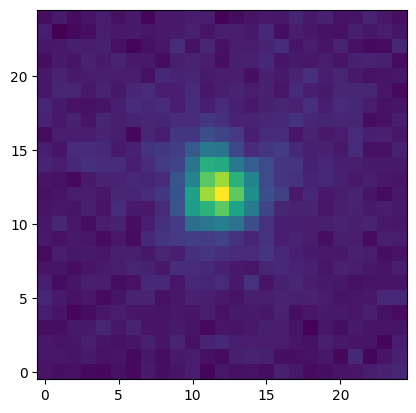

797 9


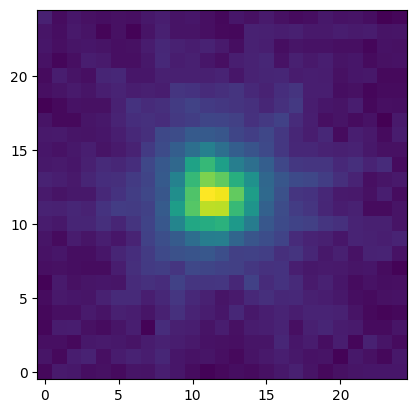

801 10


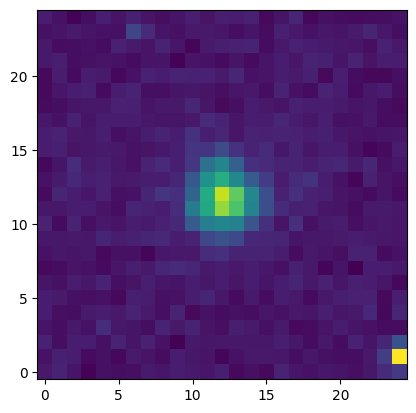

912 11


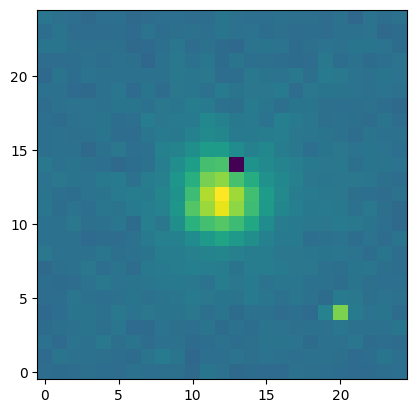

947 12


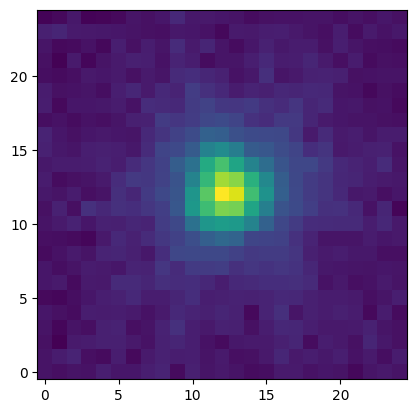

1064 13


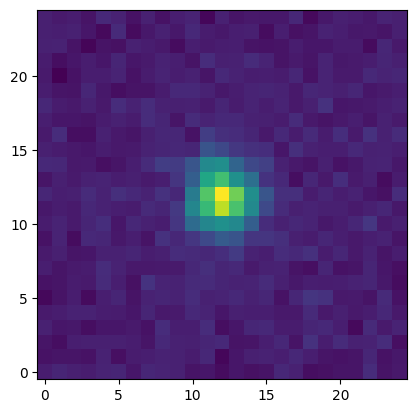

1098 14


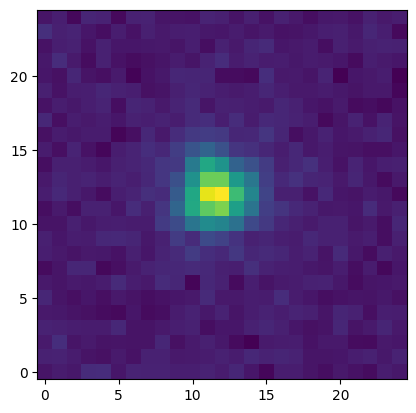

1160 15


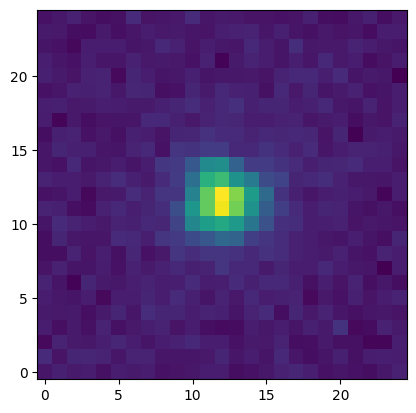

1169 16


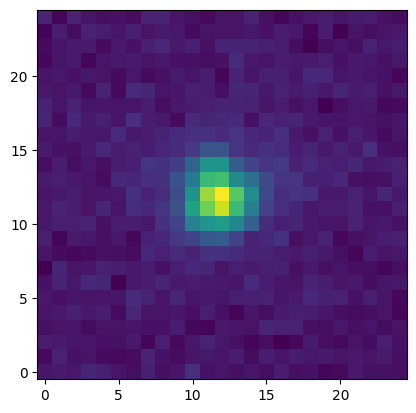

1189 17


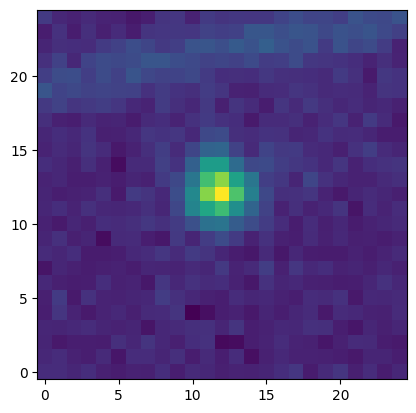

1192 18


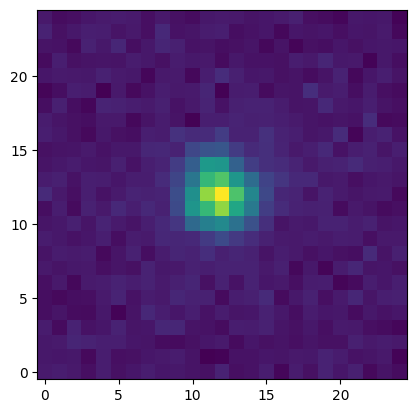

1223 19


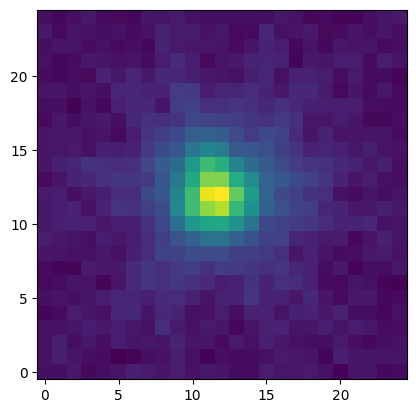

1233 20


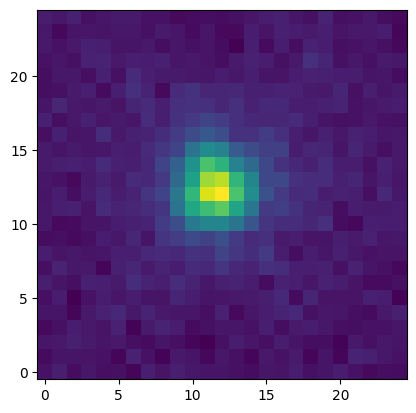

1307 21


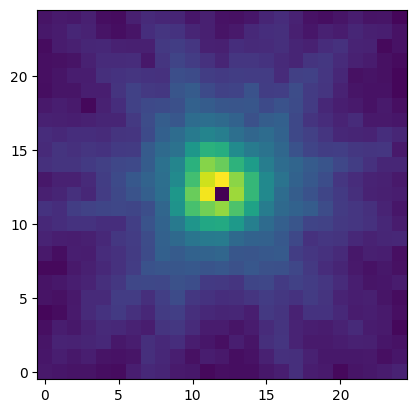

1324 22


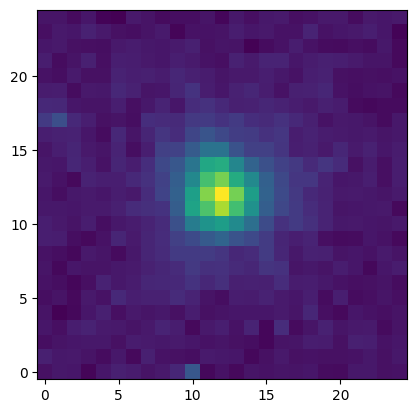

1534 23


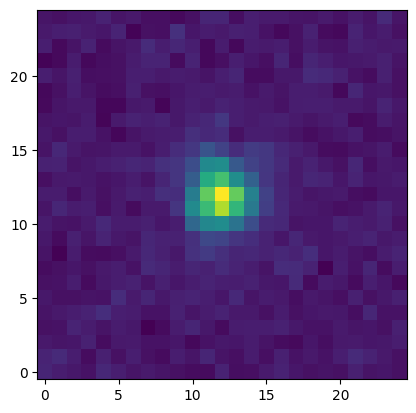

1539 24


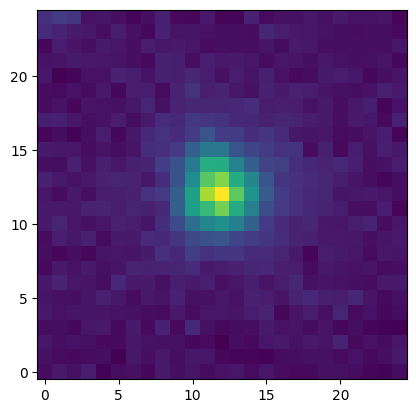

1600 25


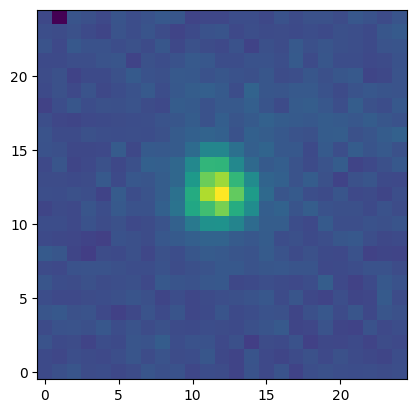

1622 26


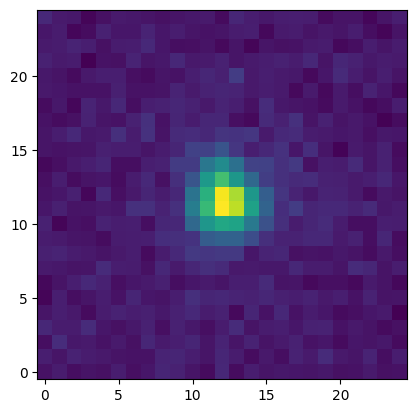

1847 27


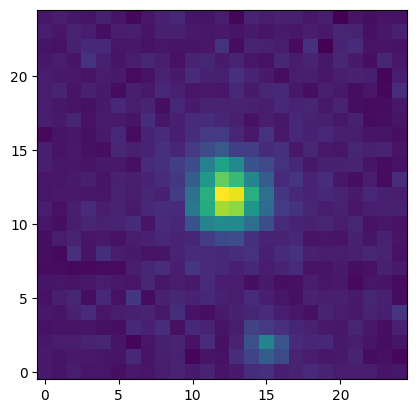

1861 28


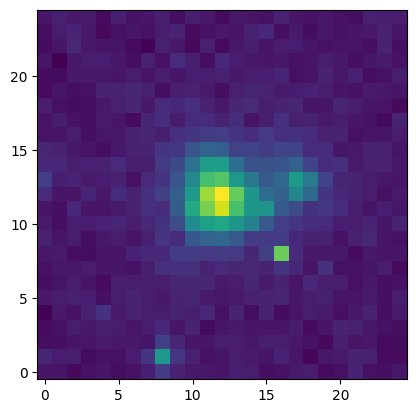

1867 29


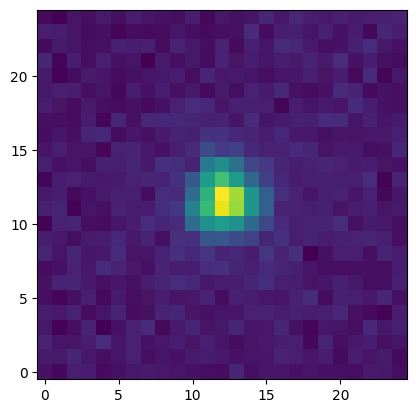

1873 30


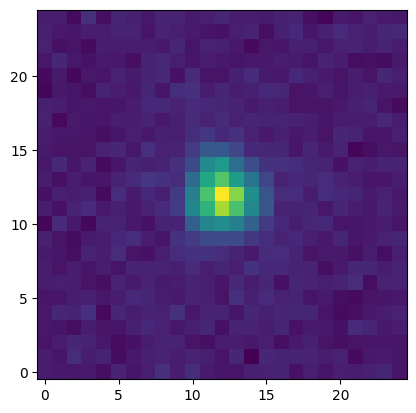

1881 31


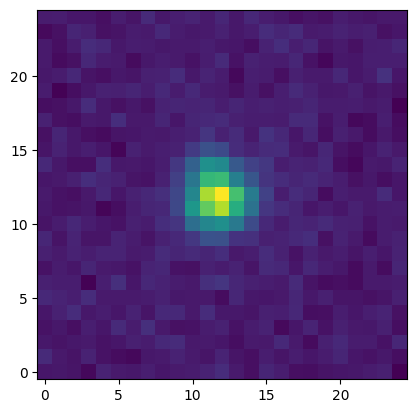

2051 32


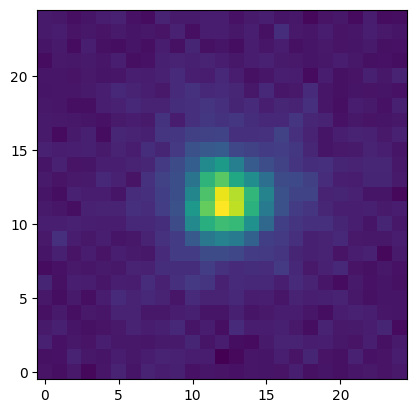

2149 33


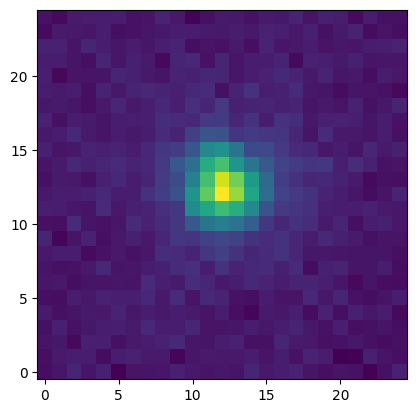

2199 34


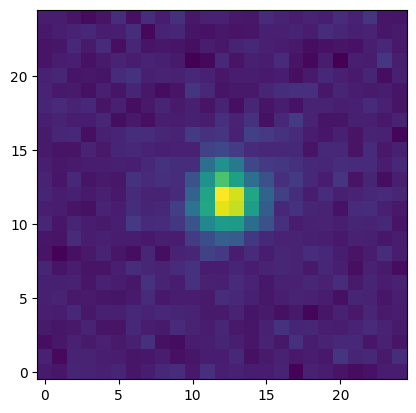

2413 35


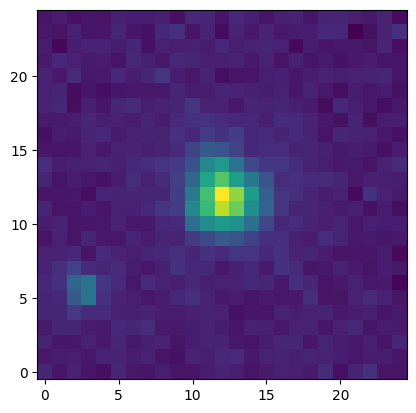

2417 36


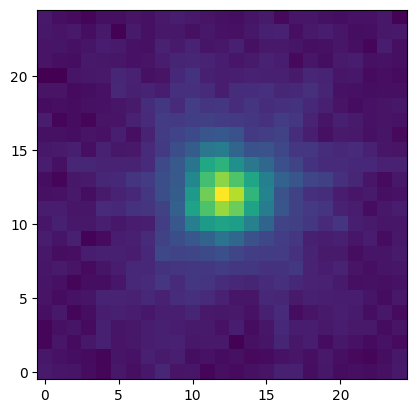

2520 37


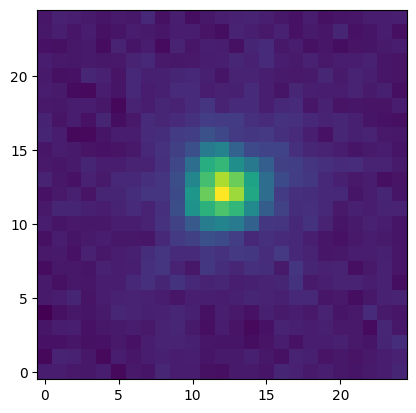

2621 38


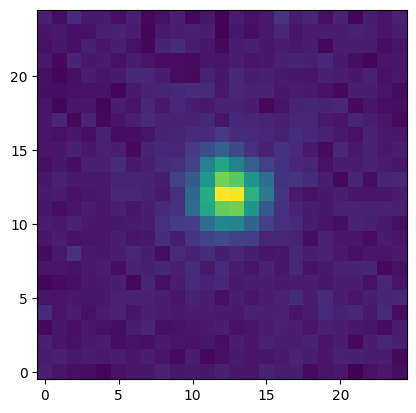

2700 39


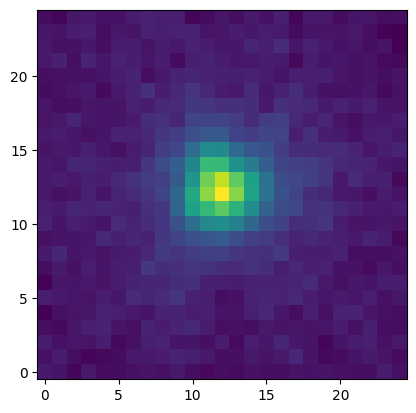

2879 40


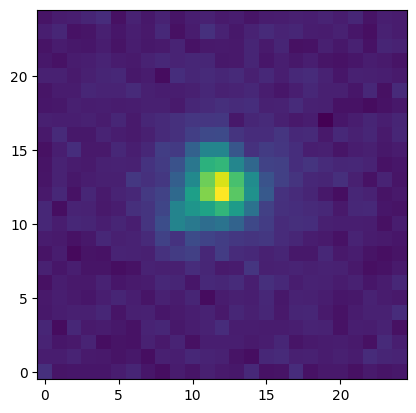

2898 41


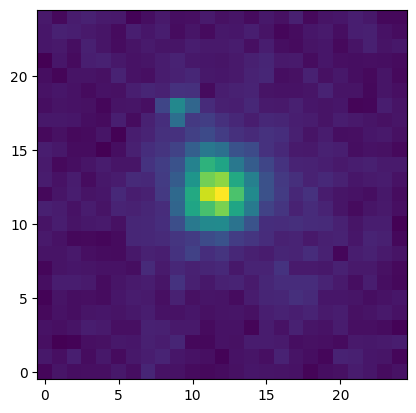

2908 42


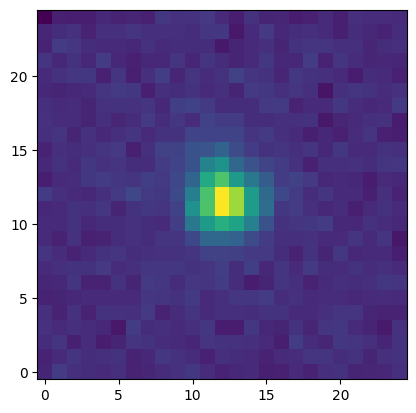

2937 43


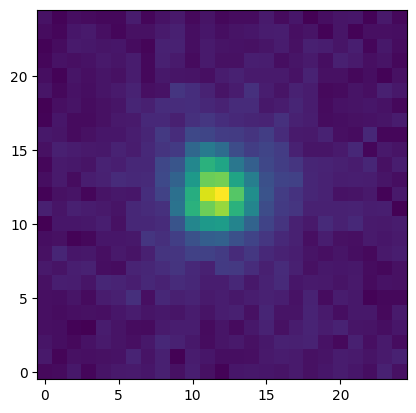

3057 44


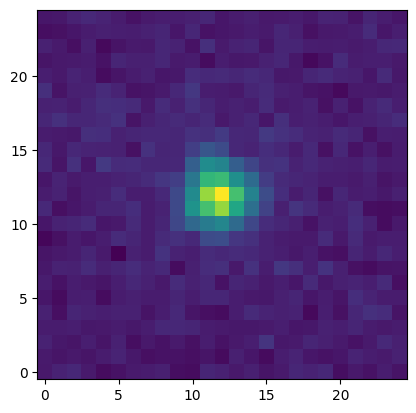

3252 45


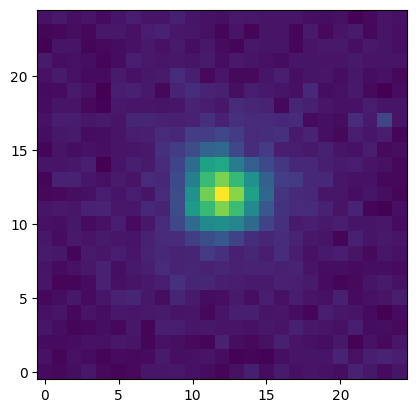

In [230]:
for k, (sdx, selstar) in enumerate(selected_stars.query("kron_abmag < 19").iterrows()):
    print(sdx,k )
    plt.imshow(stars[k].data, origin="lower", norm="asinh")
    plt.show()

In [236]:
from photutils.psf import EPSFStar, EPSFStars
from roman_cuts.com.cutout import make_cutout

# Pick an isolated star closest to the detector center so it falls in bounds across dithers
# dist_to_center = np.hypot(selected_stars["x_pix"] - nx / 2.0, selected_stars["y_pix"] - ny / 2.0)
target_star = selected_stars.iloc[36]

# Convert detector pixel coordinates to ICRS (RA, Dec) using the exposure GWCS
star_sky = gwcs.pixel_to_world(target_star["x_pix"], target_star["y_pix"])
ra_star = float(star_sky.ra.deg)
dec_star = float(star_sky.dec.deg)

print(
    f"Selected star at pixel ({target_star['x_pix']:.2f}, {target_star['y_pix']:.2f}) "
    f"-> RA={ra_star:.6f} deg, Dec={dec_star:.6f} deg"
)

# Extract cutouts of this star across all available L2 observations
l2_file_list = list(products_l2["filename"])[:200]
cutout_cubes, metadatas, gwcsss = make_cutout(
    file_names=l2_file_list,
    ra=ra_star,
    dec=dec_star,
    size=cutout_size,
    mission=mission,
    lite=False,
    n_workers=24,
    backend="thread",
)

star_cube = cutout_cubes[0]  # shape: (4, n_files, cutout_size, cutout_size) -> [flx, err, dq, dumo]
star_meta = metadatas[0]

print(f"Extracted cutout cube shape: {star_cube.shape}")
print(f"In-bounds exposures: {star_meta['in_bounds'].sum()} / {len(star_meta)}")
star_meta[["observation_id", "exposure", "mid_time", "input_position_cutout", "in_bounds"]]

Selected star at pixel (4031.20, 394.02) -> RA=250.669033 deg, Dec=36.341033 deg


Extracting cutouts:   0%|          | 0/200 [00:00<?, ?file/s]

Extracted cutout cube shape: (4, 200, 25, 25)
In-bounds exposures: 199 / 200


,observation_id,exposure,mid_time,input_position_cutout,in_bounds
0,0105501001001003001111020006,6,2461315.664890741,NaN,False
1,0105501001001004001031030002,2,2461315.669204913,"(11.56622675554263, 12.104441450037257)",True
2,0105501001001004002031030002,2,2461315.675305787,"(12.144732319045488, 12.387522389135256)",True
3,0105501001001004002031110006,6,2461315.679105023,"(12.152897069524442, 12.453404795475763)",True
4,0105501001001004003031030002,2,2461315.681370521,"(11.61143458180959, 11.81504540504011)",True
...,...,...,...,...,...
195,0105501001001013010031070004,4,2461316.3847619332,"(12.304481721488628, 11.542520885788917)",True
196,0105501001001013011031050003,3,2461316.389876858,"(12.318560563761821, 11.78819797556639)",True
197,0105501001001013011031070004,4,2461316.3908266667,"(11.853788629389783, 11.787480535699615)",True
198,0105501001001013012031030002,2,2461316.395027917,"(12.340175444933266, 11.806675473792666)",True


In [238]:
n_valid


199

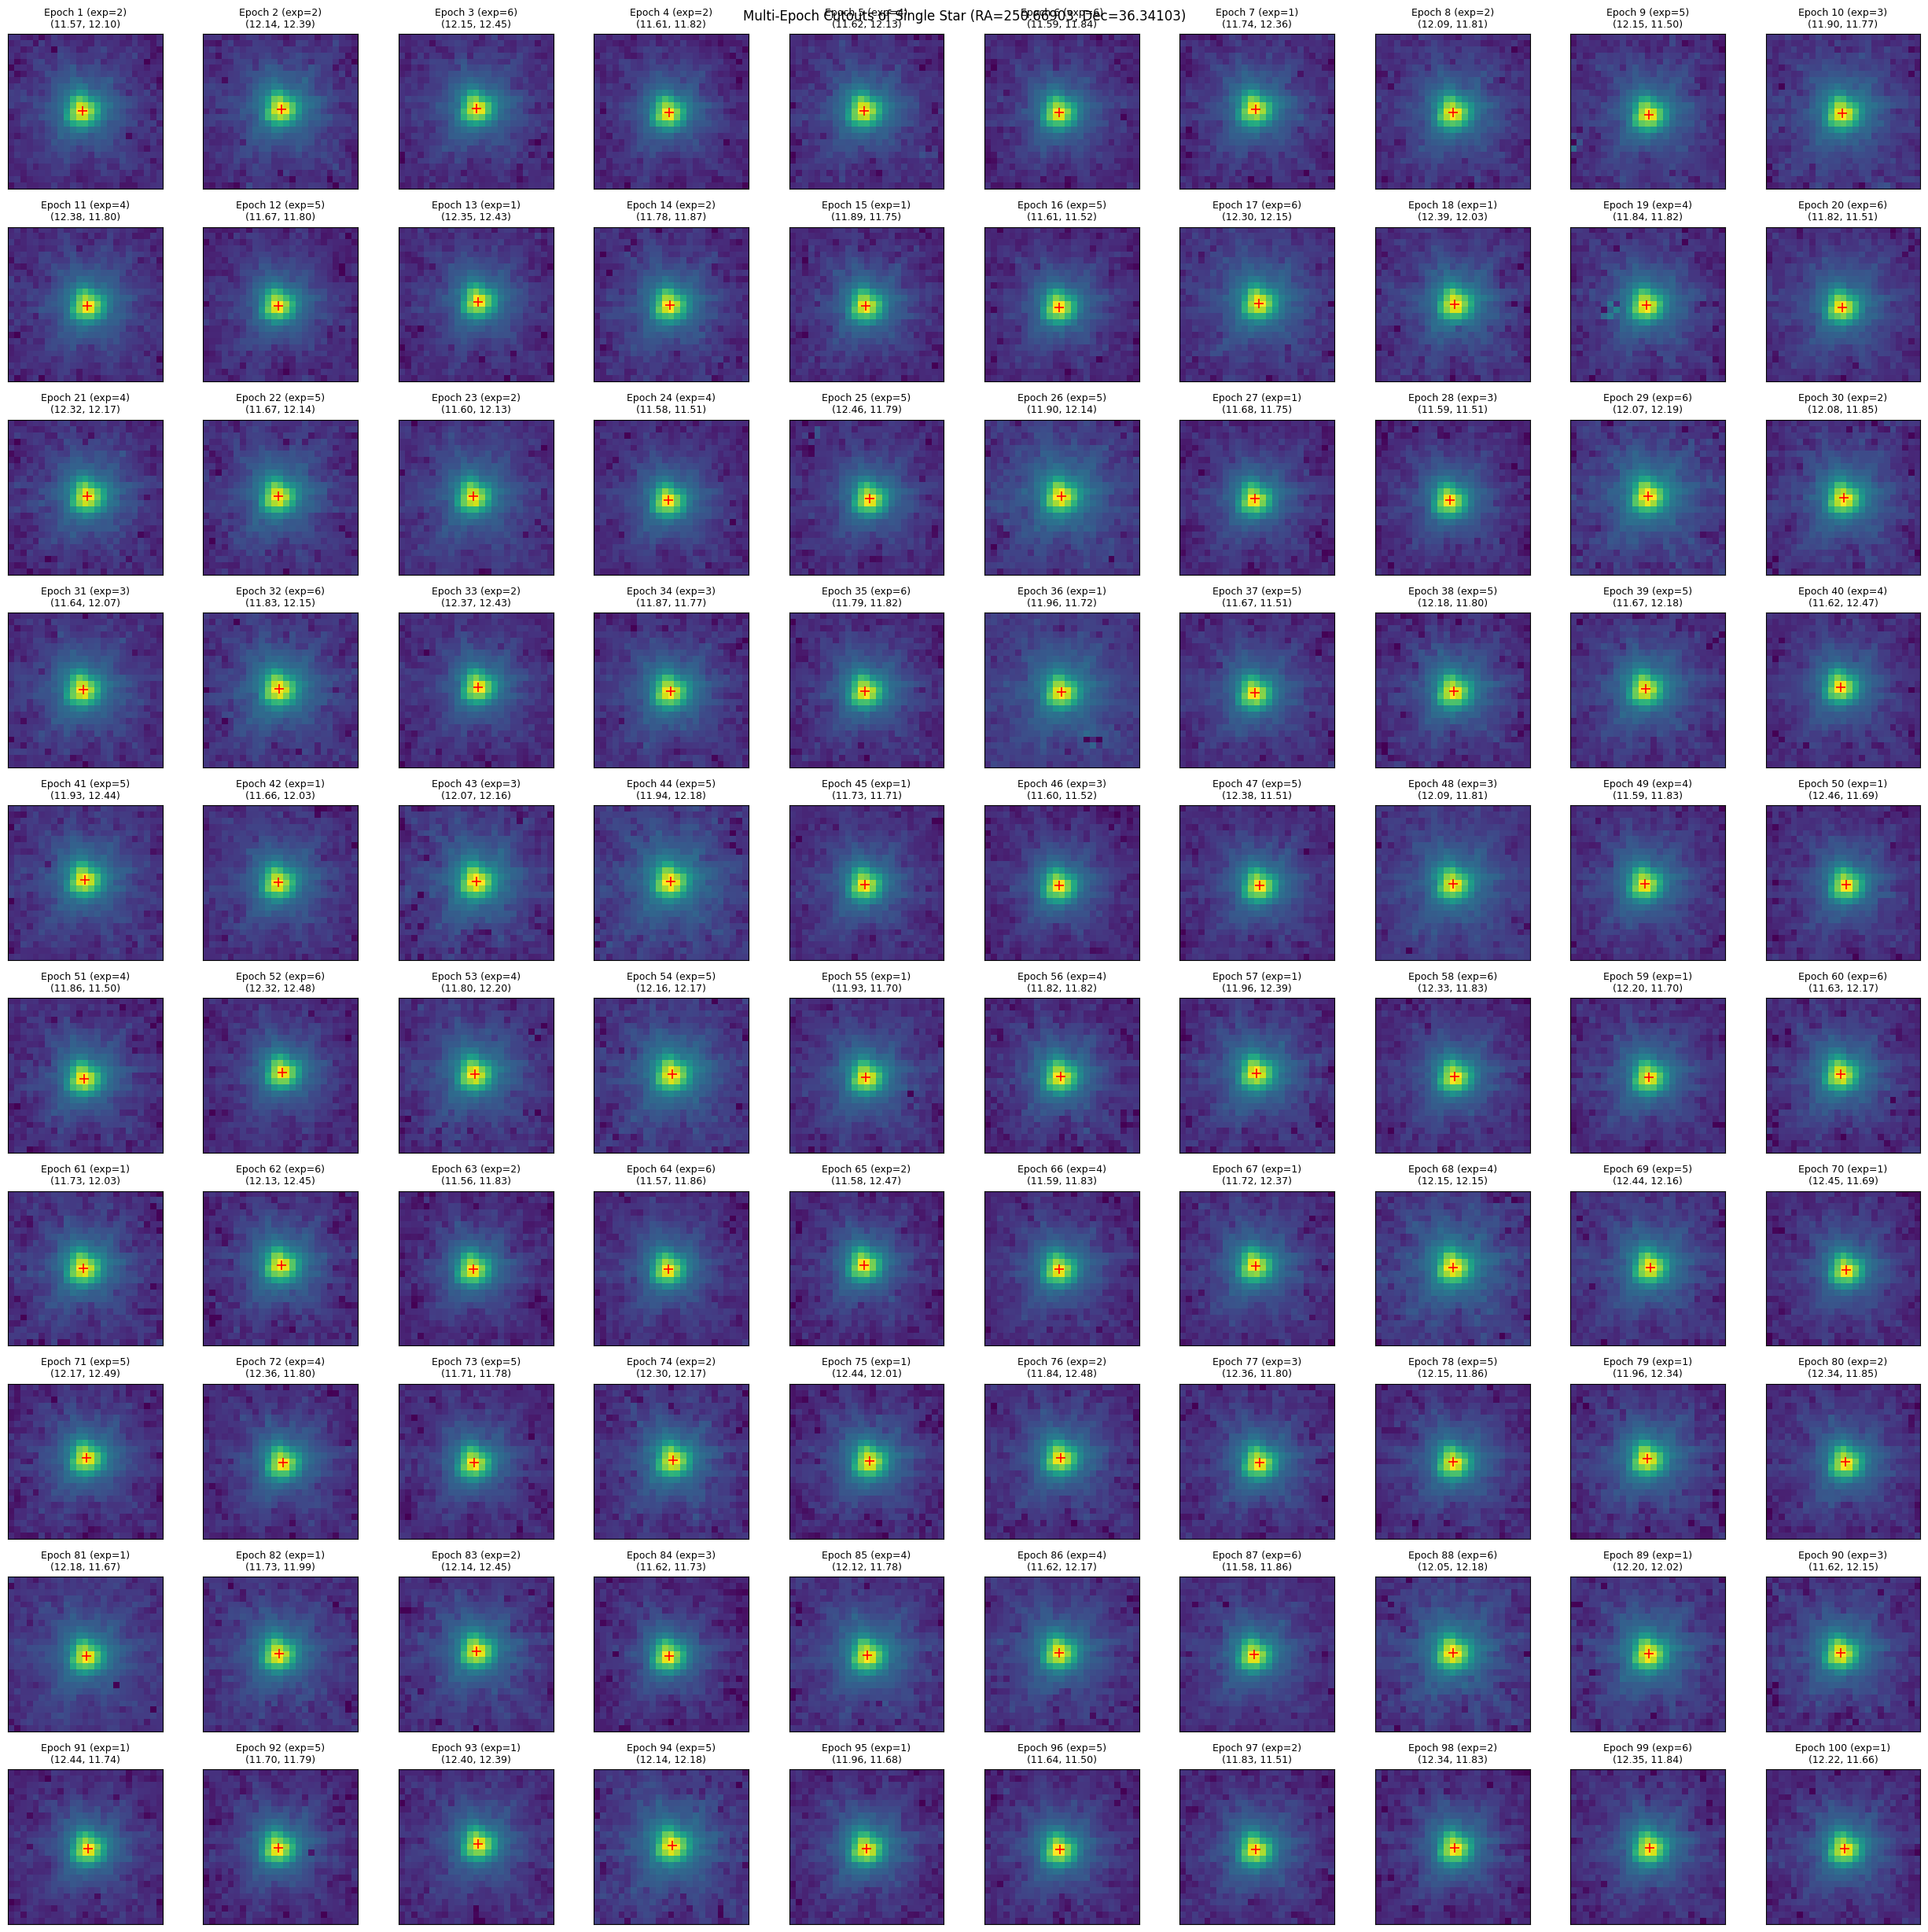

In [243]:
# Plot the extracted cutouts of the single star across all in-bounds epochs
valid_indices = star_meta.index[star_meta["in_bounds"]].to_list()
n_valid = len(valid_indices)

ncols = 10 # min(10, max(1, n_valid))
nrows = 10 # int(np.ceil(n_valid / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(2.5 * ncols, 2.5 * nrows), squeeze=False)

for plot_idx, k in enumerate(valid_indices):
    if plot_idx >= len(axes.ravel()): break
    ax = axes.ravel()[plot_idx]
    stamp_k = star_cube[0, k]
    pos_cut = star_meta.loc[k, "input_position_cutout"]
    norm_k = simple_norm(stamp_k, "log", percent=99.5)
    ax.imshow(stamp_k, norm=norm_k, origin="lower", cmap="viridis")
    if pos_cut is not None:
        ax.plot(pos_cut[0], pos_cut[1], "r+", ms=8, mew=1.2)
        title_pos = f"({pos_cut[0]:.2f}, {pos_cut[1]:.2f})"
    else:
        title_pos = ""
    ax.set_title(f"Epoch {k} (exp={star_meta.loc[k, 'exposure']})\n{title_pos}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])

for empty_idx in range(n_valid, nrows * ncols):
    axes[empty_idx // ncols, empty_idx % ncols].axis("off")

fig.suptitle(f"Multi-Epoch Cutouts of Single Star (RA={ra_star:.5f}, Dec={dec_star:.5f})", fontsize=12)
plt.tight_layout()
plt.show()

In [248]:
pixel.DO_NOT_USE.value

np.uint32(1)

In [249]:
# Convert valid epoch cutouts into photutils EPSFStar objects and build the multi-epoch ePSF
epoch_star_list = []

for k in valid_indices:
    sci_k = np.asarray(star_cube[0, k], dtype=np.float64).copy()
    dq_k = star_cube[2, k]

    bad_k = ~np.isfinite(sci_k)
    if dq_k is not None and np.any(np.isfinite(dq_k)):
        # bad_k = dq_k > 0
        bad_k = np.nan_to_num(bad_k, nan=pixel.DO_NOT_USE.value).astype(np.uint32)
        bad_k |= (dq_k & (pixel.DO_NOT_USE | pixel.SATURATED)) != 0

    if np.all(bad_k):
        continue

    # Subtract local background estimated from the cutout
    _, med_bg_k, _ = sigma_clipped_stats(sci_k[~bad_k], sigma=3.0)
    sci_clean_k = sci_k - med_bg_k
    sci_clean_k[bad_k] = 0.0
    weights_k = np.where(bad_k, 0.0, 1.0)

    pos_cut = star_meta.loc[k, "input_position_cutout"]
    orig_pos = star_meta.loc[k, "origin_original"]

    epoch_star = EPSFStar(
        sci_clean_k,
        weights=weights_k,
        cutout_center=tuple(pos_cut) if pos_cut is not None else None,
        origin=tuple(orig_pos) if orig_pos is not None else (0, 0),
        id_label=int(k),
    )
    epoch_star_list.append(epoch_star)

multi_epoch_stars = EPSFStars(epoch_star_list)
print(f"Constructed EPSFStars collection with {len(multi_epoch_stars)} epoch cutouts.")

multi_epoch_builder = EPSFBuilder(
    oversampling=oversampling,
    maxiters=maxiters,
    progress_bar=True,
    # norm_radius=5.5,
    # recentering_maxiters=20,
)

epsf_multiepoch, fitted_epoch_stars = multi_epoch_builder(multi_epoch_stars)
print(f"Built multi-epoch ePSF model with shape: {epsf_multiepoch.data.shape}")

TypeError: ufunc 'bitwise_and' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

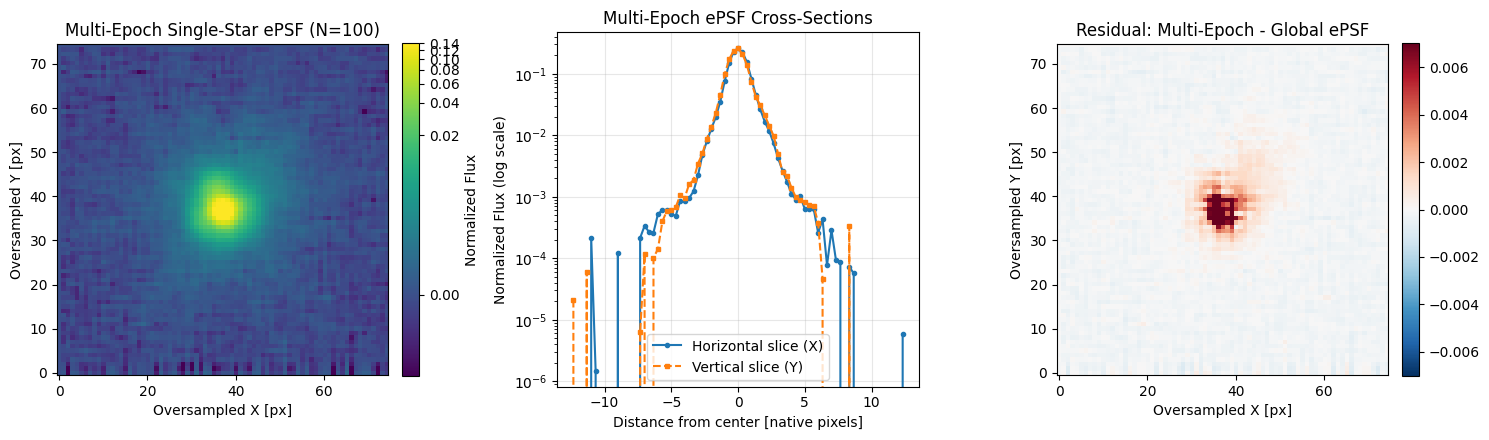

In [217]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. 2D Multi-Epoch Single-Star ePSF
norm_me = simple_norm(epsf_multiepoch.data, "log", percent=99.5)
im0 = axes[0].imshow(epsf_multiepoch.data, norm=norm_me, origin="lower", cmap="viridis")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label="Normalized Flux")
axes[0].set_title(f"Multi-Epoch Single-Star ePSF (N={len(multi_epoch_stars)})")
axes[0].set_xlabel("Oversampled X [px]")
axes[0].set_ylabel("Oversampled Y [px]")

# 2. 1D Central Cross-Sections
cy_me, cx_me = np.unravel_index(np.nanargmax(epsf_multiepoch.data), epsf_multiepoch.data.shape)
px_me = (np.arange(epsf_multiepoch.data.shape[1]) - cx_me) / oversampling
py_me = (np.arange(epsf_multiepoch.data.shape[0]) - cy_me) / oversampling
axes[1].plot(px_me, epsf_multiepoch.data[cy_me, :], "o-", ms=3, label="Horizontal slice (X)")
axes[1].plot(py_me, epsf_multiepoch.data[:, cx_me], "s--", ms=3, label="Vertical slice (Y)")
axes[1].set_yscale("log")
axes[1].set_xlabel("Distance from center [native pixels]")
axes[1].set_ylabel("Normalized Flux (log scale)")
axes[1].set_title("Multi-Epoch ePSF Cross-Sections")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# 3. Difference against Global ePSF (over overlapping region)
mh = min(epsf_multiepoch.data.shape[0], epsf_global.data.shape[0])
mw = min(epsf_multiepoch.data.shape[1], epsf_global.data.shape[1])
diff_me = epsf_multiepoch.data[:mh, :mw] - epsf_global.data[:mh, :mw]
vmax_me = np.nanpercentile(np.abs(diff_me), 99.5)
im2 = axes[2].imshow(diff_me, origin="lower", cmap="RdBu_r", vmin=-vmax_me, vmax=vmax_me)
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)
axes[2].set_title("Residual: Multi-Epoch - Global ePSF")
axes[2].set_xlabel("Oversampled X [px]")
axes[2].set_ylabel("Oversampled Y [px]")

plt.tight_layout()
plt.show()

## 8. Saving and Loading an `ImagePSF` Model to/from a FITS File

To reuse a reconstructed `ImagePSF` (or `EPSFModel`) later without rebuilding it, we save its 2D oversampled PSF array in a FITS Primary HDU along with all model parameters required to reconstruct the exact `ImagePSF` instance (`oversampling`, `origin`, `flux`, `x_0`, `y_0`, parameter `fixed` flags, `interp_kwargs`, and optional instrument metadata).

In [33]:
import json
from pathlib import Path
from astropy.io import fits
from photutils.psf import ImagePSF


def save_image_psf_to_fits(
    psf_model: ImagePSF,
    filename: str | Path,
    extra_header: dict | None = None,
    overwrite: bool = True,
) -> Path:
    """Save a photutils ImagePSF (or EPSFModel) object to a FITS file.

    Stores the 2D PSF array in the PrimaryHDU data and records all parameters
    needed to reconstruct the ImagePSF model (`oversampling`, `origin`,
    `flux`, `x_0`, `y_0`, fixed parameter flags, and `interp_kwargs`) in the
    FITS header.

    Parameters
    ----------
    psf_model : photutils.psf.ImagePSF
        The ePSF / ImagePSF model instance to save.
    filename : str or Path
        Output FITS file path.
    extra_header : dict or None, optional
        Additional header keyword/value pairs (e.g., filter, detector, norm_radius).
    overwrite : bool, optional
        Whether to overwrite an existing file (default: True).

    Returns
    -------
    Path
        Resolved path to the written FITS file.
    """
    hdr = fits.Header()
    hdr["MODELCLS"] = (psf_model.__class__.__name__, "photutils PSF model class")

    # Oversampling (can be scalar or 2-element (ox, oy) in photutils)
    ov = np.atleast_1d(psf_model.oversampling)
    ox, oy = (int(ov[0]), int(ov[0])) if len(ov) == 1 else (int(ov[0]), int(ov[1]))
    hdr["OVERSMPX"] = (ox, "PSF oversampling factor along X")
    hdr["OVERSMPY"] = (oy, "PSF oversampling factor along Y")

    # Origin of the PSF center in array pixel coordinates
    if hasattr(psf_model, "origin") and psf_model.origin is not None:
        orig = np.atleast_1d(psf_model.origin)
        hdr["ORIGIN_X"] = (float(orig[0]), "PSF center X origin in data array")
        hdr["ORIGIN_Y"] = (float(orig[1]), "PSF center Y origin in data array")

    # Model parameters & fixed flags
    hdr["FLUX"] = (float(psf_model.flux.value), "Default model flux scaling factor")
    hdr["X_0"] = (float(psf_model.x_0.value), "Default model X center position")
    hdr["Y_0"] = (float(psf_model.y_0.value), "Default model Y center position")
    hdr["FIX_FLUX"] = (bool(psf_model.flux.fixed), "Whether flux parameter is fixed")
    hdr["FIX_X0"] = (bool(psf_model.x_0.fixed), "Whether x_0 parameter is fixed")
    hdr["FIX_Y0"] = (bool(psf_model.y_0.fixed), "Whether y_0 parameter is fixed")

    # Interpolation kwargs used by RectBivariateSpline
    interp_kw = getattr(psf_model, "interp_kwargs", None)
    if interp_kw:
        if "kx" in interp_kw:
            hdr["INTERPKX"] = (int(interp_kw["kx"]), "Spline interpolation degree in X")
        if "ky" in interp_kw:
            hdr["INTERPKY"] = (int(interp_kw["ky"]), "Spline interpolation degree in Y")
        hdr["INTERPKW"] = (json.dumps(interp_kw), "JSON-encoded interp_kwargs")

    if extra_header:
        for k, v in extra_header.items():
            hdr[k] = v

    psf_array = np.asarray(psf_model.data, dtype=np.float64)
    hdu = fits.PrimaryHDU(data=psf_array, header=hdr)

    out_path = Path(filename)
    hdu.writeto(out_path, overwrite=overwrite)
    return out_path


def load_image_psf_from_fits(filename: str | Path) -> tuple[ImagePSF, fits.Header]:
    """Load a photutils ImagePSF model and its FITS header from a FITS file.

    Parameters
    ----------
    filename : str or Path
        Path to the FITS file created by `save_image_psf_to_fits`.

    Returns
    -------
    psf_model : photutils.psf.ImagePSF
        Reconstructed ImagePSF object ready for evaluation or PSF photometry.
    header : astropy.io.fits.Header
        FITS header containing the saved metadata.
    """
    with fits.open(filename) as hdul:
        psf_data = np.asarray(hdul[0].data, dtype=np.float64).copy()
        hdr = hdul[0].header.copy()

    ox = int(hdr.get("OVERSMPX", 1))
    oy = int(hdr.get("OVERSMPY", ox))
    oversampling = ox if ox == oy else (ox, oy)

    origin = None
    if "ORIGIN_X" in hdr and "ORIGIN_Y" in hdr:
        origin = (float(hdr["ORIGIN_X"]), float(hdr["ORIGIN_Y"]))

    interp_kwargs = None
    if "INTERPKW" in hdr:
        interp_kwargs = json.loads(hdr["INTERPKW"])
    elif "INTERPKX" in hdr or "INTERPKY" in hdr:
        interp_kwargs = {
            "kx": int(hdr.get("INTERPKX", 3)),
            "ky": int(hdr.get("INTERPKY", 3)),
        }

    psf_model = ImagePSF(
        data=psf_data,
        flux=float(hdr.get("FLUX", 1.0)),
        x_0=float(hdr.get("X_0", 0.0)),
        y_0=float(hdr.get("Y_0", 0.0)),
        oversampling=oversampling,
        origin=origin,
        # interp_kwargs=interp_kwargs,
    )
    psf_model.flux.fixed = bool(hdr.get("FIX_FLUX", False))
    psf_model.x_0.fixed = bool(hdr.get("FIX_X0", False))
    psf_model.y_0.fixed = bool(hdr.get("FIX_Y0", False))

    return psf_model, hdr

In [42]:
OUT_PATH = "/home/jorgemarpa/teams/romcom/data/jmartinez/data/ePSF"
OUT_PATH = os.path.join(OUT_PATH, f"program_{pid}")
os.makedirs(OUT_PATH, exist_ok=True)

# Save the global ePSF model to a FITS file and reload it
fits_out = f"{OUT_PATH}/roman_epsf_pid{pid}_wfi{detector:02d}_{filter_name.lower()}-global.fits"

saved_path = save_image_psf_to_fits(
    epsf,
    fits_out,
    extra_header={
        "INSTRUME": ("WFI", "Roman Wide Field Instrument"),
        "DETECTOR": (f"WFI{detector:02d}", "Detector identifier"),
        "FILTER": (filter_name, "Optical element / filter"),
        "CUTSIZE": (cutout_size, "Star cutout size [native px]"),
        "NORMRAD": (5.5, "Normalization radius [native px]"),
        "NSTARS": (len(stars), "Number of stars used in EPSFBuilder"),
        "ASDF_REF": (str(asdf_filename), "Reference L2 ASDF exposure"),
    },
)
print(f"Saved ImagePSF to: {saved_path}")

# Reload the ImagePSF from FITS and verify exact reconstruction
loaded_epsf, loaded_hdr = load_image_psf_from_fits(saved_path)

yy_test, xx_test = np.mgrid[-5:6, -5:6]
orig_eval = epsf.evaluate(xx_test, yy_test, flux=1.0, x_0=0.25, y_0=-0.15)
load_eval = loaded_epsf.evaluate(xx_test, yy_test, flux=1.0, x_0=0.25, y_0=-0.15)

print("Data arrays match     :", np.allclose(epsf.data, loaded_epsf.data))
print("Evaluated stamps match:", np.allclose(orig_eval, load_eval))
print("\nSaved FITS Header:")
print(repr(loaded_hdr))

Saved ImagePSF to: /home/jorgemarpa/teams/romcom/data/jmartinez/data/ePSF/program_1055/roman_epsf_pid1055_wfi04_f146-global.fits
Data arrays match     : True
Evaluated stamps match: True

Saved FITS Header:
SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -64 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                  101                                                  
NAXIS2  =                  101                                                  
MODELCLS= 'ImagePSF'           / photutils PSF model class                      
OVERSMPX=                    4 / PSF oversampling factor along X                
OVERSMPY=                    4 / PSF oversampling factor along Y                
ORIGIN_X=                 50.0 / PSF center X origin in data array              
ORIGIN_Y=                 50.0 / PSF center Y origin in data arr